<a href="https://colab.research.google.com/github/Isaq0711/processamento-sinais-I/blob/main/aula-06/codigo/aula_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AP6 — Transformadas de Wavelets (e transformada de Hadamard)
**GELE7317 — Processamento de Sinais I** — Prof. Rafael S. Chaves

Resolução das questões da Atividade Prática 6: (1) transformada de
Hadamard em um sistema CDMA com ruído AWGN; (2) resumo sobre wavelets
(respondido no relatório); (3) análise de um sinal não estacionário por
wavelet biortogonal 7–9 (`bior4.4`); (4) remoção de ruído do sinal
`leleccum.mat` por limiarização de coeficientes de wavelet (`db4`) e
por limiarização da DFT.

> Dados necessários em `dados/`: apenas `leleccum.mat` (Questão 4).
> O sinal da Questão 3 é gerado no próprio notebook, com o código do
> script `non_stationary_signal.ipynb` do repositório da disciplina.
> Rode as células em ordem.


## Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy.fft import fft, fftfreq
from scipy.linalg import hadamard
from scipy.special import erfc
import pywt
import os

PASTA_DADOS = "dados"  # leleccum.mat deve estar nesta pasta

# No Google Colab, use o bloco abaixo para enviar o arquivo de dados:
# from google.colab import files
# uploaded = files.upload()  # selecione leleccum.mat
# PASTA_DADOS = "."

# (PyWavelets: pip install PyWavelets)

In [ ]:
def calculate_spectrum(signal, sampling_frequency, single_sided=True):
    """
    Calcula o espectro de amplitude de um sinal.
    (Função fornecida pelo professor — repositório gele7317-proc-sin.)

    Retorna (frequencies, amplitudes); com single_sided=True, apenas as
    frequências positivas, com amplitude 1/N * |FFT|.
    """
    N = len(signal)  # número de amostras
    T = 1.0 / sampling_frequency  # período de amostragem

    yf = fft(signal)

    if single_sided:
        xf = fftfreq(N, T)[:N//2]
        amplitudes = 1.0/N * np.abs(yf[0:N//2])
    else:
        xf = fftfreq(N, T)
        amplitudes = 1.0/N * np.abs(yf)

    return xf, amplitudes


def q_func(x):
    """Função Q: P(Z > x) para Z ~ N(0, 1)."""
    return 0.5 * erfc(x / np.sqrt(2.0))

## Questão 1 — Transformada de Hadamard em um sistema CDMA

**Modelo adotado.** Cada usuário $k$ transmite uma sequência de
$8$ símbolos $m_k[n]\in\{-1,+1\}$, $n=0,\dots,7$. Cada símbolo é
espalhado por um código de Hadamard de comprimento $8$ (8 *chips* por
símbolo): o símbolo $m_k[n]$ multiplica o código $\mathbf{c}_k$, de
modo que o sinal codificado do usuário $k$ tem $8\times 8=64$ chips,
$x_k=[\,m_k[0]\mathbf{c}_k,\;m_k[1]\mathbf{c}_k,\dots,m_k[7]\mathbf{c}_k\,]$.

Os códigos são linhas da matriz de Hadamard $\mathbf{H}_8$, que satisfaz
$\mathbf{H}_8\mathbf{H}_8^T = 8\,\mathbf{I}_8$ (linhas ortogonais). Os
três usuários recebem as linhas 1, 2 e 3 (a linha 0 é composta só de
$+1$ e não alteraria o sinal).


In [ ]:
N_CHIPS = 8                 # comprimento do código = chips por símbolo
N_SIMBOLOS = 8              # comprimento de cada sequência m_k[n]
LINHAS_CODIGO = [1, 2, 3]   # linha de H8 atribuída a cada usuário
N_USUARIOS = len(LINHAS_CODIGO)

C = hadamard(N_CHIPS).astype(float)       # matriz de códigos (cada linha = um código)
print("C @ C.T == 8*I ?", np.allclose(C @ C.T, N_CHIPS * np.eye(N_CHIPS)))
codigos = C[LINHAS_CODIGO]                # 3 x 8
print("Códigos dos usuários:")
print(codigos.astype(int))

rng_msg = np.random.default_rng(42)       # semente fixa -> resultados reproduzíveis
M = rng_msg.choice([-1.0, 1.0], size=(N_USUARIOS, N_SIMBOLOS))   # m_k[n]
print("Mensagens m_k[n]:")
print(M.astype(int))


def codificar(m, c):
    """Espalha cada símbolo de m pelo código c: kron(m, c) = [m0*c, m1*c, ...]."""
    return np.kron(m, c)


X = np.array([codificar(M[k], codigos[k]) for k in range(N_USUARIOS)])   # 3 x 64
y_sem_ruido = X.sum(axis=0)                                              # soma dos usuários

# Conferência da forma matricial: coluna n de Y = soma_k m_k[n] c_k
Y_mat = codigos.T @ M                                                    # chips x símbolos (8 x 8)
print("Forma matricial confere com a soma dos sinais codificados?",
      np.allclose(Y_mat.flatten(order="F"), y_sem_ruido))

C @ C.T == 8*I ? True
Códigos dos usuários:
[[ 1 -1  1 -1  1 -1  1 -1]
 [ 1  1 -1 -1  1  1 -1 -1]
 [ 1 -1 -1  1  1 -1 -1  1]]
Mensagens m_k[n]:
[[-1  1  1 -1 -1  1 -1  1]
 [-1 -1  1  1  1  1  1  1]
 [ 1 -1  1 -1  1 -1 -1  1]]
Forma matricial confere com a soma dos sinais codificados? True


### (a) Sinal original, código e sinal codificado de cada usuário

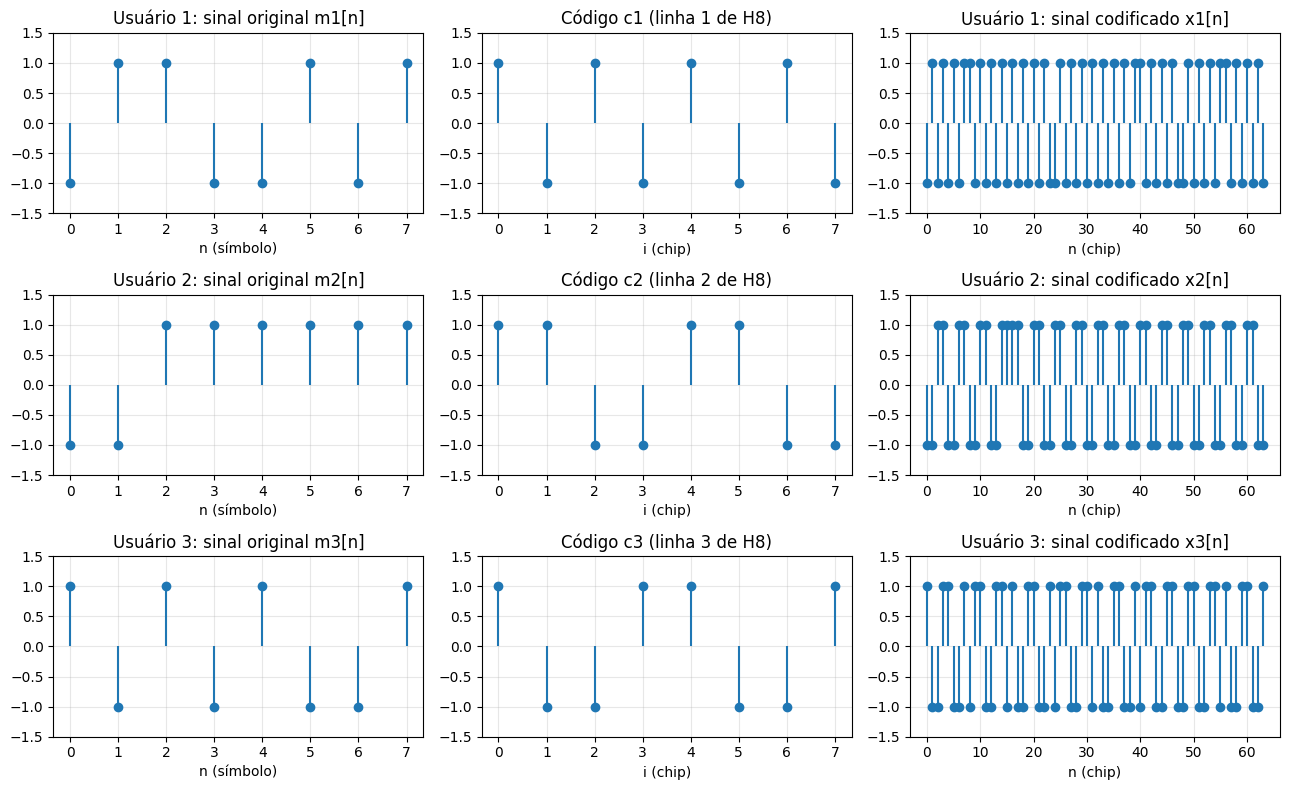

In [ ]:
fig, eixos = plt.subplots(N_USUARIOS, 3, figsize=(13, 8))
for k in range(N_USUARIOS):
    eixos[k, 0].stem(np.arange(N_SIMBOLOS), M[k], basefmt=" ")
    eixos[k, 0].set_title(f"Usuário {k+1}: sinal original m{k+1}[n]")
    eixos[k, 0].set_xlabel("n (símbolo)")
    eixos[k, 0].set_ylim(-1.5, 1.5)

    eixos[k, 1].stem(np.arange(N_CHIPS), codigos[k], basefmt=" ")
    eixos[k, 1].set_title(f"Código c{k+1} (linha {LINHAS_CODIGO[k]} de H8)")
    eixos[k, 1].set_xlabel("i (chip)")
    eixos[k, 1].set_ylim(-1.5, 1.5)

    eixos[k, 2].stem(np.arange(N_SIMBOLOS * N_CHIPS), X[k], basefmt=" ")
    eixos[k, 2].set_title(f"Usuário {k+1}: sinal codificado x{k+1}[n]")
    eixos[k, 2].set_xlabel("n (chip)")
    eixos[k, 2].set_ylim(-1.5, 1.5)
    for ax in eixos[k]:
        ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Usuário 1: frequência do maior pico — original: 0.0469, codificado: 0.4531 ciclos/chip
Usuário 2: frequência do maior pico — original: 0.0156, codificado: 0.2500 ciclos/chip
Usuário 3: frequência do maior pico — original: 0.0469, codificado: 0.2969 ciclos/chip


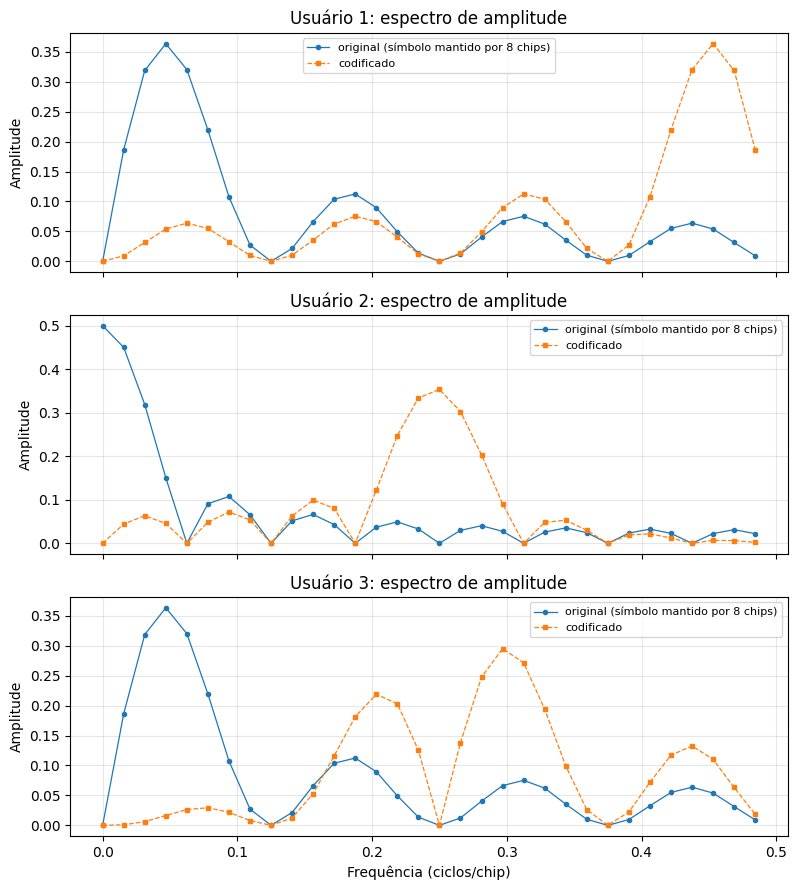

In [ ]:
# Espectros: o sinal original é "mantido" por 8 chips (mesma taxa de amostragem
# do sinal codificado), para que ambos possam ser comparados no mesmo eixo.
# Frequência normalizada: 1 chip = 1 amostra -> eixo em ciclos/chip (0 a 0,5).
FS_CHIP = 1.0
fig, eixos = plt.subplots(N_USUARIOS, 1, figsize=(8, 9), sharex=True)
for k in range(N_USUARIOS):
    f_o, a_o = calculate_spectrum(np.repeat(M[k], N_CHIPS), FS_CHIP)
    f_c, a_c = calculate_spectrum(X[k], FS_CHIP)
    eixos[k].plot(f_o, a_o, "o-", ms=3, lw=0.9, label="original (símbolo mantido por 8 chips)")
    eixos[k].plot(f_c, a_c, "s--", ms=3, lw=0.9, label="codificado")
    eixos[k].set_title(f"Usuário {k+1}: espectro de amplitude")
    eixos[k].set_ylabel("Amplitude")
    eixos[k].grid(True, alpha=0.3)
    eixos[k].legend(fontsize=8)
    print(f"Usuário {k+1}: frequência do maior pico — original: {f_o[np.argmax(a_o[1:])+1]:.4f}, "
          f"codificado: {f_c[np.argmax(a_c)]:.4f} ciclos/chip")
eixos[-1].set_xlabel("Frequência (ciclos/chip)")
plt.tight_layout()
plt.show()

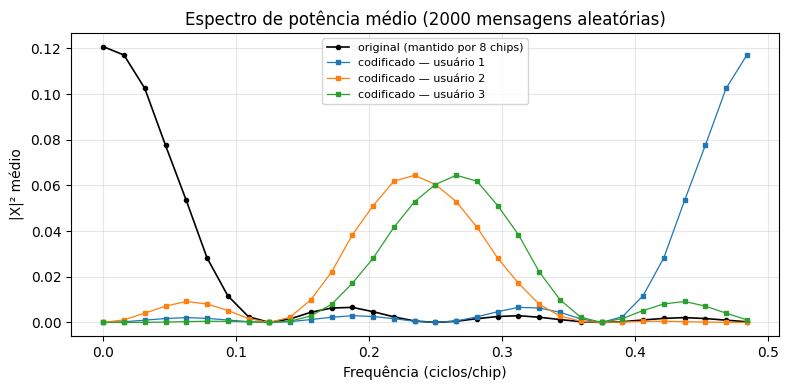

In [ ]:
# Densidade espectral média (2000 mensagens aleatórias): mostra o efeito
# estatístico da codificação, sem depender de uma única realização.
rng_psd = np.random.default_rng(7)
N_REAL = 2000
psd_orig = 0.0
psd_cod = np.zeros((N_USUARIOS, N_SIMBOLOS * N_CHIPS // 2))
for _ in range(N_REAL):
    m = rng_psd.choice([-1.0, 1.0], size=N_SIMBOLOS)
    freqs, a = calculate_spectrum(np.repeat(m, N_CHIPS), FS_CHIP)
    psd_orig = psd_orig + a ** 2
    for k in range(N_USUARIOS):
        _, a = calculate_spectrum(codificar(m, codigos[k]), FS_CHIP)
        psd_cod[k] += a ** 2
psd_orig /= N_REAL
psd_cod /= N_REAL

plt.figure(figsize=(8, 4))
plt.plot(freqs, psd_orig, "k-o", ms=3, lw=1.2, label="original (mantido por 8 chips)")
for k in range(N_USUARIOS):
    plt.plot(freqs, psd_cod[k], "-s", ms=3, lw=0.9, label=f"codificado — usuário {k+1}")
plt.xlabel("Frequência (ciclos/chip)")
plt.ylabel("|X|² médio")
plt.title(f"Espectro de potência médio ({N_REAL} mensagens aleatórias)")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### (b) Sinal recebido y[n] = x₁[n] + x₂[n] + x₃[n] + w[n]

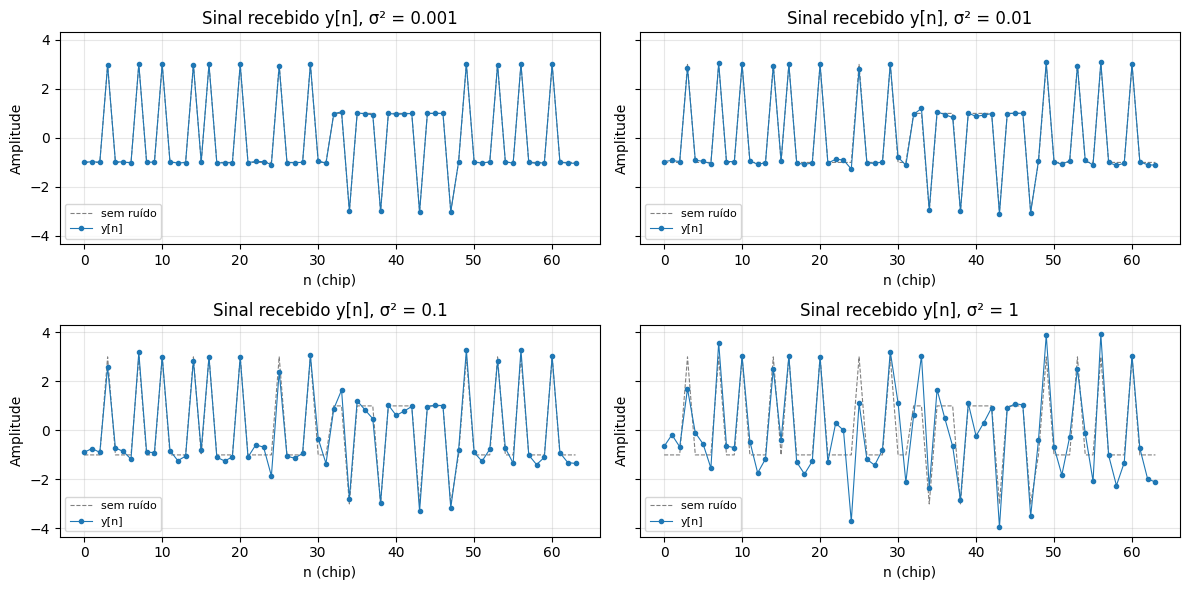

In [ ]:
SIGMA2_LISTA = [1e-3, 1e-2, 1e-1, 1.0]
z = np.random.default_rng(1).standard_normal(y_sem_ruido.size)   # ruído-base N(0,1), fixo
# w[n] = sqrt(sigma²) * z[n]: só a variância muda entre os casos
y_ruidoso = {s2: y_sem_ruido + np.sqrt(s2) * z for s2 in SIGMA2_LISTA}

fig, eixos = plt.subplots(2, 2, figsize=(12, 6), sharey=True)
for ax, s2 in zip(eixos.ravel(), SIGMA2_LISTA):
    ax.plot(y_sem_ruido, "--", color="gray", lw=0.8, label="sem ruído")
    ax.plot(y_ruidoso[s2], "o-", ms=3, lw=0.8, label="y[n]")
    ax.set_title(f"Sinal recebido y[n], σ² = {s2:g}")
    ax.set_xlabel("n (chip)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

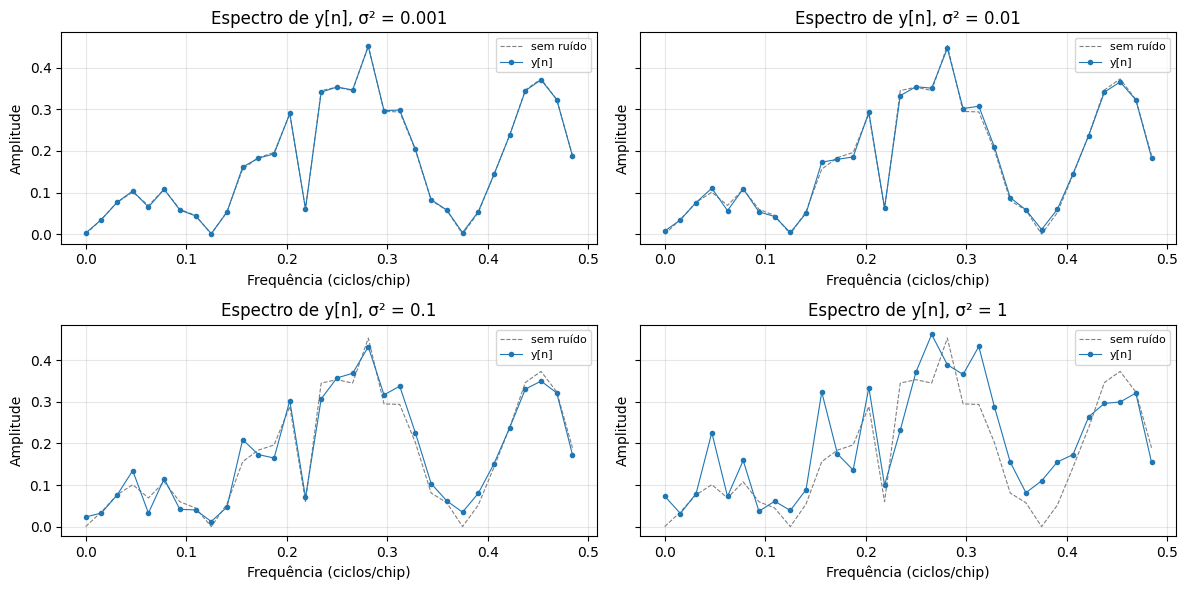

In [ ]:
fig, eixos = plt.subplots(2, 2, figsize=(12, 6), sharey=True)
f_ref, a_ref = calculate_spectrum(y_sem_ruido, FS_CHIP)
for ax, s2 in zip(eixos.ravel(), SIGMA2_LISTA):
    f_y, a_y = calculate_spectrum(y_ruidoso[s2], FS_CHIP)
    ax.plot(f_ref, a_ref, "--", color="gray", lw=0.8, label="sem ruído")
    ax.plot(f_y, a_y, "o-", ms=3, lw=0.8, label="y[n]")
    ax.set_title(f"Espectro de y[n], σ² = {s2:g}")
    ax.set_xlabel("Frequência (ciclos/chip)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### (c) Recuperação de $m_k[n]$ a partir de $y[n]$ (notação vetorial)

Para cada instante de símbolo $n$, o vetor de $8$ chips recebidos é

$$\mathbf{y}[n]=\sum_{j} m_j[n]\,\mathbf{c}_j+\mathbf{w}[n]=\mathbf{C}^T\mathbf{m}[n]+\mathbf{w}[n],$$

com $\mathbf{C}\in\mathbb{R}^{8\times8}$ (códigos nas linhas, $\mathbf{C}\mathbf{C}^T=8\mathbf{I}$),
$\mathbf{m}[n]=[m_1[n],m_2[n],m_3[n],0,\dots,0]^T$ e
$\mathbf{w}[n]\sim\mathcal{N}(\mathbf{0},\sigma^2\mathbf{I}_8)$.

**Receptor (correlator).** Multiplicando por $\tfrac18\mathbf{C}$:

$$\hat{\mathbf{m}}[n]=\tfrac18\mathbf{C}\,\mathbf{y}[n]=\tfrac18\mathbf{C}\mathbf{C}^T\mathbf{m}[n]+\tfrac18\mathbf{C}\mathbf{w}[n]=\mathbf{m}[n]+\tfrac18\mathbf{C}\mathbf{w}[n].$$

Para o usuário $k$: $\;\hat m_k[n]=m_k[n]+\tfrac18\,\mathbf{c}_k^T\mathbf{w}[n]$.
Os demais usuários **não aparecem** na estimativa (ortogonalidade).

**Impacto do ruído.** $\tfrac18\mathbf{c}_k^T\mathbf{w}[n]$ é gaussiano, de média nula e variância
$\tfrac1{64}\,\mathbf{c}_k^T(\sigma^2\mathbf{I})\mathbf{c}_k=\tfrac{8\sigma^2}{64}=\sigma^2/8$.
O ganho de processamento é $8$: a variância do ruído na estimativa é $8$ vezes
menor que a variância por chip. Com decisão $\hat m_k[n]=\operatorname{sign}(\cdot)$, o erro ocorre
quando o ruído supera $1$ em sentido contrário:

$$P_e=Q\!\left(\sqrt{8/\sigma^2}\right).$$


### (d) Estimativa de m̂ₖ[n] e probabilidade de erro × σ²

In [ ]:
def receptor_correlador(Y, C_rx):
    """m_hat = (1/8) * C_rx @ Y, com Y (chips x símbolos) e C_rx (usuários x chips)."""
    return C_rx @ Y / N_CHIPS


print("Comparação m_k[n] x m̂_k[n] (uma realização, as mesmas mensagens de (a)):")
for s2 in SIGMA2_LISTA:
    Y = y_ruidoso[s2].reshape(N_CHIPS, N_SIMBOLOS, order="F")
    M_soft = receptor_correlador(Y, codigos)
    M_hat = np.sign(M_soft)
    erros = int(np.sum(M_hat != M))
    print(f"  σ² = {s2:<6g}: {erros} erro(s) em {M.size} símbolos;"
          f"  desvio máx. |m̂ - m| = {np.max(np.abs(M_soft - M)):.3f}")
Y = y_ruidoso[1.0].reshape(N_CHIPS, N_SIMBOLOS, order="F")
print("\nσ² = 1 — usuário 1:")
print("  m  :", M[0].astype(int))
print("  m̂  :", np.round(receptor_correlador(Y, codigos)[0], 2))

Comparação m_k[n] x m̂_k[n] (uma realização, as mesmas mensagens de (a)):
  σ² = 0.001 : 0 erro(s) em 24 símbolos;  desvio máx. |m̂ - m| = 0.019
  σ² = 0.01  : 0 erro(s) em 24 símbolos;  desvio máx. |m̂ - m| = 0.061
  σ² = 0.1   : 0 erro(s) em 24 símbolos;  desvio máx. |m̂ - m| = 0.193
  σ² = 1     : 0 erro(s) em 24 símbolos;  desvio máx. |m̂ - m| = 0.609

σ² = 1 — usuário 1:
  m  : [-1  1  1 -1 -1  1 -1  1]
  m̂  : [-0.94  0.74  1.05 -0.67 -1.16  1.08 -0.5   0.99]


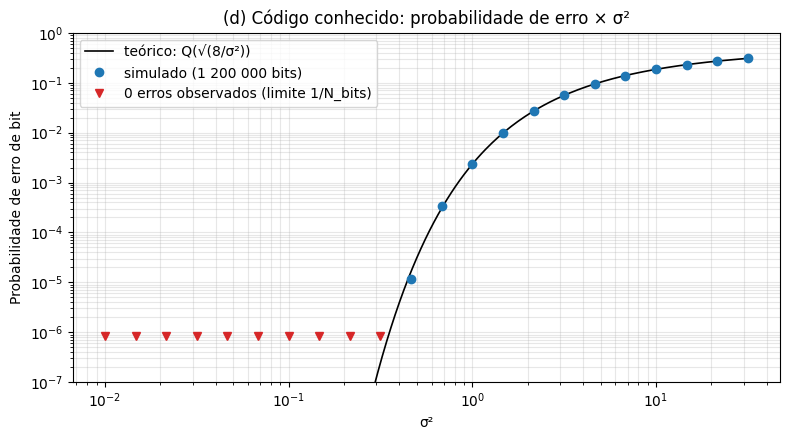

σ² =   1.00: simulado = 2.3192e-03 | teórico = 2.3389e-03
σ² =   1.47: simulado = 9.8892e-03 | teórico = 9.7823e-03
σ² =   2.15: simulado = 2.7067e-02 | teórico = 2.6991e-02
σ² =   3.16: simulado = 5.6018e-02 | teórico = 5.5856e-02
σ² =   4.64: simulado = 9.5168e-02 | teórico = 9.4619e-02
σ² =   6.81: simulado = 1.3932e-01 | teórico = 1.3927e-01
σ² =  10.00: simulado = 1.8555e-01 | teórico = 1.8555e-01


In [ ]:
N_BLOCOS = 50000   # blocos de 8 símbolos x 3 usuários = 24 bits por bloco


def simular_erro_awgn(sigma2, n_blocos, rng):
    """Probabilidade de erro de bit (Monte Carlo) com ruído AWGN e código conhecido."""
    M_ = rng.choice([-1.0, 1.0], size=(n_blocos, N_USUARIOS, N_SIMBOLOS))
    ruido = np.sqrt(sigma2) * rng.standard_normal((n_blocos, N_CHIPS, N_SIMBOLOS))
    Y_ = np.einsum("kc,tkn->tcn", codigos, M_) + ruido
    M_hat = np.einsum("kc,tcn->tkn", codigos, Y_) / N_CHIPS
    return np.mean(np.sign(M_hat) != M_)


sigma2_grade = np.logspace(-2, 1.5, 22)
rng_mc = np.random.default_rng(2)
pe_sim_d = np.array([simular_erro_awgn(s2, N_BLOCOS, rng_mc) for s2 in sigma2_grade])
sigma2_fino = np.logspace(-2, 1.5, 300)
pe_teo_d = q_func(np.sqrt(N_CHIPS / sigma2_fino))
n_bits = N_BLOCOS * N_USUARIOS * N_SIMBOLOS

plt.figure(figsize=(8, 4.5))
plt.semilogy(sigma2_fino, pe_teo_d, "k-", lw=1.2, label="teórico: Q(√(8/σ²))")
medidos = pe_sim_d > 0
plt.semilogy(sigma2_grade[medidos], pe_sim_d[medidos], "o", label=f"simulado ({n_bits:,} bits)".replace(",", " "))
if np.any(~medidos):
    plt.semilogy(sigma2_grade[~medidos], np.full((~medidos).sum(), 1.0 / n_bits), "v",
                 color="tab:red", label="0 erros observados (limite 1/N_bits)")
plt.xscale("log")
plt.ylim(1e-7, 1)
plt.xlabel("σ²")
plt.ylabel("Probabilidade de erro de bit")
plt.title("(d) Código conhecido: probabilidade de erro × σ²")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

for s2, pe in zip(sigma2_grade, pe_sim_d):
    if 0.9 <= s2 <= 12:
        print(f"σ² = {s2:6.2f}: simulado = {pe:.4e} | teórico = {q_func(np.sqrt(8/s2)):.4e}")

### (e) Código distorcido no receptor: $\hat{\mathbf{C}}=\mathbf{C}+\mathbf{W}$, com $w[n]=0$

Com $\mathbf{w}[n]=\mathbf{0}$, $\mathbf{y}[n]=\mathbf{C}^T\mathbf{m}[n]$ e o receptor usa $\hat{\mathbf{C}}$:

$$\hat{\mathbf{m}}[n]=\tfrac18\hat{\mathbf{C}}\,\mathbf{y}[n]=\tfrac18(\mathbf{C}+\mathbf{W})\mathbf{C}^T\mathbf{m}[n]=\mathbf{m}[n]+\tfrac18\,\mathbf{W}\mathbf{C}^T\mathbf{m}[n].$$

Para o usuário $k$, com $\mathbf{w}_k^T$ a $k$-ésima linha de $\mathbf{W}$ (entradas i.i.d. $\mathcal{N}(0,\sigma^2)$):

$$\hat m_k[n]=m_k[n]+\tfrac18\sum_{j\,\in\,\text{ativos}} m_j[n]\,\big(\mathbf{w}_k^T\mathbf{c}_j\big).$$

Cada $a_{kj}=\mathbf{w}_k^T\mathbf{c}_j\sim\mathcal{N}(0,8\sigma^2)$, e, como os códigos são ortogonais,
$a_{kj}$ e $a_{ki}$ ($i\neq j$) são **independentes**. Com $J=3$ usuários ativos
(inclusive o termo $j=k$, que distorce o próprio símbolo), a perturbação em $\hat m_k[n]$ é gaussiana, de
variância $J\cdot 8\sigma^2/64 = J\sigma^2/8$. Logo

$$P_e=Q\!\left(\sqrt{\frac{8}{J\sigma^2}}\right)=Q\!\left(\sqrt{\frac{8}{3\sigma^2}}\right).$$

A distorção do código **perde a ortogonalidade**: a estimativa de cada usuário passa a conter
interferência dos outros usuários (e do próprio símbolo, em ganho $\neq 1$), e a variância do erro
cresce com o número de usuários ativos — ao contrário do caso (c), em que o ruído era independente
do número de usuários.


### (f) Código distorcido: m̂ₖ[n] e probabilidade de erro × σ²

Exemplo (σ² = 0,5): erros = 0 de 24
  m  (usuário 1): [-1  1  1 -1 -1  1 -1  1]
  m̂  (usuário 1): [-0.97  0.75  1.88 -1.66 -0.75  0.97 -1.66  1.88]


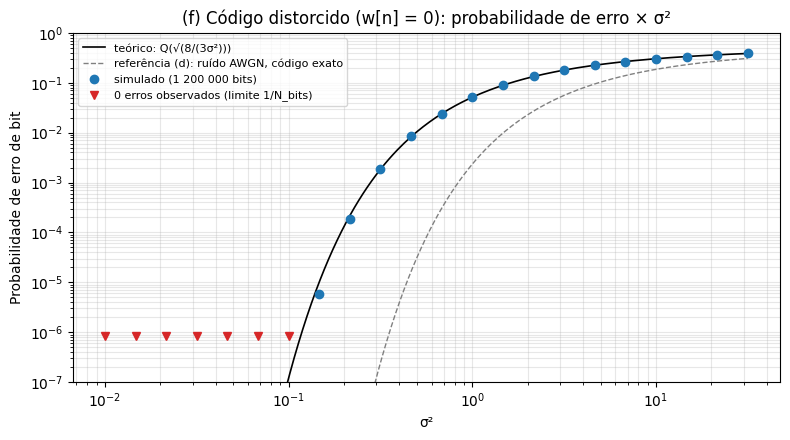

σ² =   0.32: simulado = 1.8617e-03 | teórico = 1.8426e-03
σ² =   0.46: simulado = 8.3750e-03 | teórico = 8.2671e-03
σ² =   0.68: simulado = 2.3637e-02 | teórico = 2.3941e-02
σ² =   1.00: simulado = 5.0847e-02 | teórico = 5.1235e-02
σ² =   1.47: simulado = 8.9042e-02 | teórico = 8.8849e-02
σ² =   2.15: simulado = 1.3342e-01 | teórico = 1.3295e-01
σ² =   3.16: simulado = 1.7861e-01 | teórico = 1.7923e-01
σ² =   4.64: simulado = 2.2386e-01 | teórico = 2.2423e-01
σ² =   6.81: simulado = 2.6589e-01 | teórico = 2.6578e-01
σ² =  10.00: simulado = 3.0104e-01 | teórico = 3.0279e-01


In [ ]:
def simular_erro_codigo_distorcido(sigma2, n_blocos, rng):
    """Probabilidade de erro de bit com w[n] = 0 e código do receptor C_hat = C + W."""
    M_ = rng.choice([-1.0, 1.0], size=(n_blocos, N_USUARIOS, N_SIMBOLOS))
    Y_ = np.einsum("kc,tkn->tcn", codigos, M_)                       # sem ruído aditivo
    C_hat = codigos[None, :, :] + np.sqrt(sigma2) * rng.standard_normal((n_blocos, N_USUARIOS, N_CHIPS))
    M_hat = np.einsum("tkc,tcn->tkn", C_hat, Y_) / N_CHIPS
    return np.mean(np.sign(M_hat) != M_)


# Exemplo de uma realização (mesmas mensagens de (a)), σ² = 0,5
rng_ex = np.random.default_rng(3)
W_ex = np.sqrt(0.5) * rng_ex.standard_normal((N_USUARIOS, N_CHIPS))
M_hat_ex = receptor_correlador(Y_mat, codigos + W_ex)
print("Exemplo (σ² = 0,5): erros =", int(np.sum(np.sign(M_hat_ex) != M)), "de", M.size)
print("  m  (usuário 1):", M[0].astype(int))
print("  m̂  (usuário 1):", np.round(M_hat_ex[0], 2))

rng_mc2 = np.random.default_rng(4)
pe_sim_f = np.array([simular_erro_codigo_distorcido(s2, N_BLOCOS, rng_mc2) for s2 in sigma2_grade])
pe_teo_f = q_func(np.sqrt(N_CHIPS / (N_USUARIOS * sigma2_fino)))

plt.figure(figsize=(8, 4.5))
plt.semilogy(sigma2_fino, pe_teo_f, "k-", lw=1.2, label="teórico: Q(√(8/(3σ²)))")
plt.semilogy(sigma2_fino, pe_teo_d, "--", color="gray", lw=1.0, label="referência (d): ruído AWGN, código exato")
medidos = pe_sim_f > 0
plt.semilogy(sigma2_grade[medidos], pe_sim_f[medidos], "o", label=f"simulado ({n_bits:,} bits)".replace(",", " "))
if np.any(~medidos):
    plt.semilogy(sigma2_grade[~medidos], np.full((~medidos).sum(), 1.0 / n_bits), "v",
                 color="tab:red", label="0 erros observados (limite 1/N_bits)")
plt.xscale("log")
plt.ylim(1e-7, 1)
plt.xlabel("σ²")
plt.ylabel("Probabilidade de erro de bit")
plt.title("(f) Código distorcido (w[n] = 0): probabilidade de erro × σ²")
plt.grid(True, which="both", alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

for s2, pe in zip(sigma2_grade, pe_sim_f):
    if 0.3 <= s2 <= 12:
        print(f"σ² = {s2:6.2f}: simulado = {pe:.4e} | teórico = {q_func(np.sqrt(8/(3*s2))):.4e}")

## Questão 2 — Resumo sobre transformadas de wavelets e aplicações

O resumo pedido é **textual** e está no relatório (Seção II). As células abaixo trazem
apenas duas ilustrações complementares: (i) as funções de escala e de wavelet das famílias
usadas neste trabalho e (ii) a comparação entre a divisão do plano tempo–frequência da STFT
(janela fixa) e a da transformada de wavelet diádica.


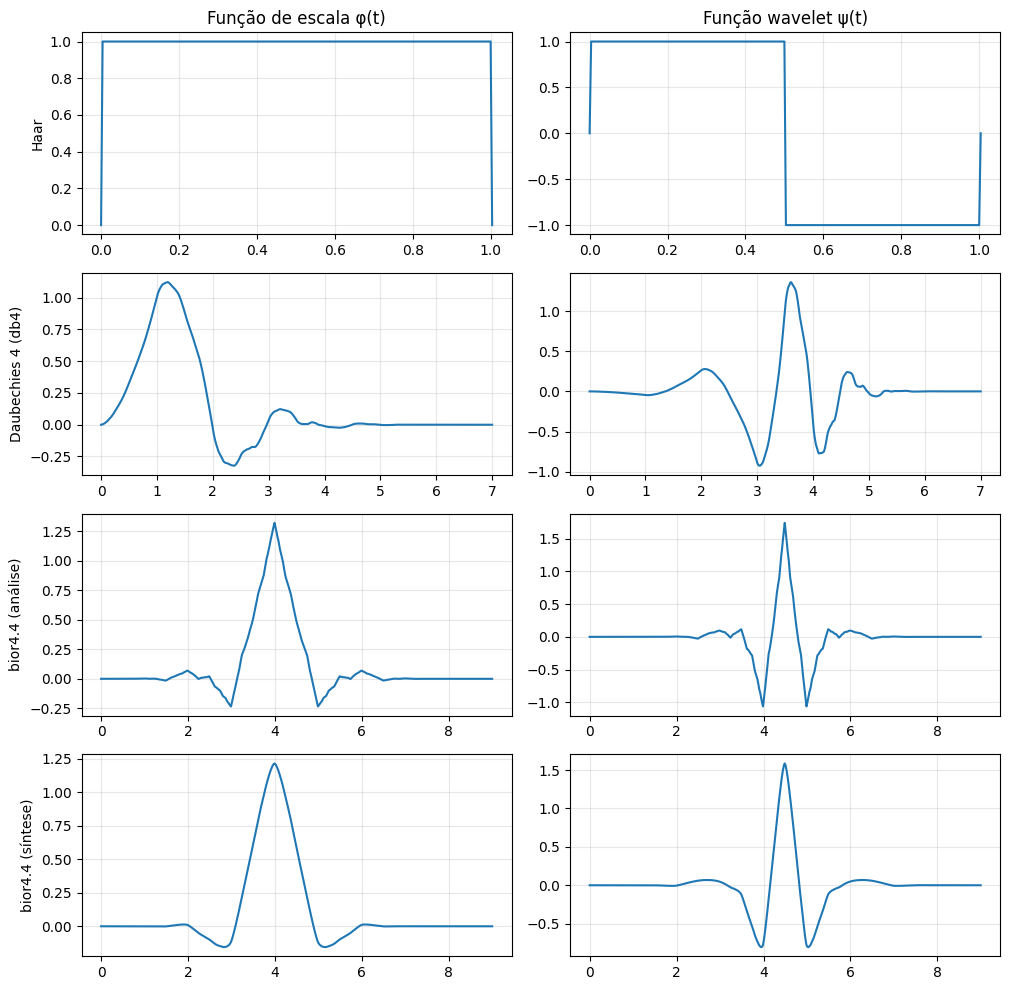

In [ ]:
fig, eixos = plt.subplots(4, 2, figsize=(10, 10))

phi, psi, xs = pywt.Wavelet("haar").wavefun(level=8)
eixos[0, 0].plot(xs, phi); eixos[0, 1].plot(xs, psi)
eixos[0, 0].set_ylabel("Haar")

phi, psi, xs = pywt.Wavelet("db4").wavefun(level=8)
eixos[1, 0].plot(xs, phi); eixos[1, 1].plot(xs, psi)
eixos[1, 0].set_ylabel("Daubechies 4 (db4)")

phi_d, psi_d, phi_r, psi_r, xs = pywt.Wavelet("bior4.4").wavefun(level=8)
eixos[2, 0].plot(xs, phi_d); eixos[2, 1].plot(xs, psi_d)
eixos[2, 0].set_ylabel("bior4.4 (análise)")
eixos[3, 0].plot(xs, phi_r); eixos[3, 1].plot(xs, psi_r)
eixos[3, 0].set_ylabel("bior4.4 (síntese)")

eixos[0, 0].set_title("Função de escala φ(t)")
eixos[0, 1].set_title("Função wavelet ψ(t)")
for ax in eixos.ravel():
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

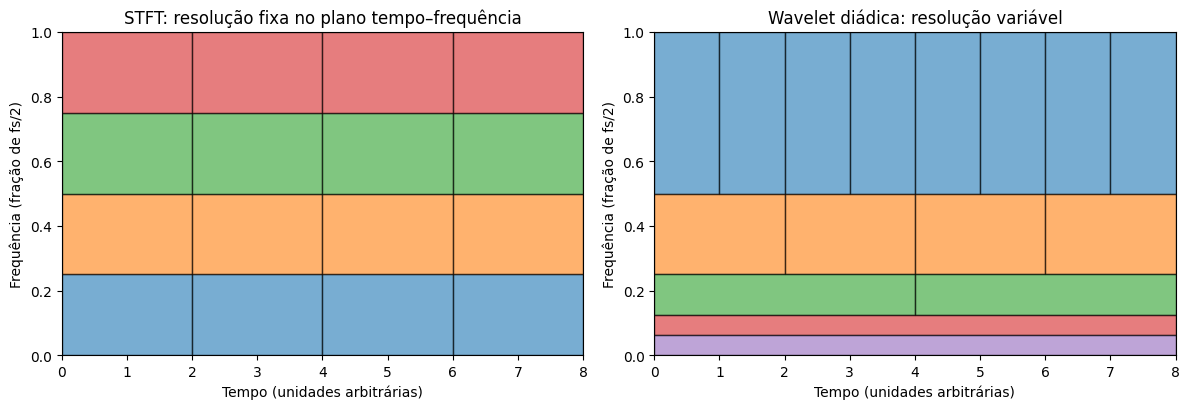

In [ ]:
from matplotlib.patches import Rectangle

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2))
cores = plt.cm.tab10.colors

# STFT: janela fixa -> retângulos uniformes (largura 2 no tempo, 0,25 na frequência)
for i in range(4):
    for j in range(4):
        eixos[0].add_patch(Rectangle((2 * i, 0.25 * j), 2, 0.25, fc=cores[j], ec="k", alpha=0.6))
eixos[0].set_title("STFT: resolução fixa no plano tempo–frequência")

# Wavelet diádica: baixa frequência -> caixas longas no tempo; alta frequência -> caixas curtas
niveis = [(0.5, 1.0, 1, 0), (0.25, 0.5, 2, 1), (0.125, 0.25, 4, 2), (0.0625, 0.125, 8, 3), (0.0, 0.0625, 8, 4)]
for f0, f1, largura, c in niveis:
    for t0 in np.arange(0, 8, largura):
        eixos[1].add_patch(Rectangle((t0, f0), largura, f1 - f0, fc=cores[c], ec="k", alpha=0.6))
eixos[1].set_title("Wavelet diádica: resolução variável")

for ax in eixos:
    ax.set_xlim(0, 8)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Tempo (unidades arbitrárias)")
    ax.set_ylabel("Frequência (fração de fs/2)")
plt.tight_layout()
plt.show()

## Questão 3 — Sinal não estacionário e wavelet 7–9 (`bior4.4`)

### (a) O sinal gerado pelo script `non_stationary_signal.ipynb`
O código abaixo é o do script do repositório da disciplina (variáveis renomeadas para
`x_ns`, `t_ns`, `N_ns`, apenas para não colidir com as demais questões).


In [ ]:
# ===== Código do script non_stationary_signal.ipynb (Prof. Rafael S. Chaves) =====
N_ns = 2000                                          # Signal length
t_ns = np.arange(N_ns + 1)                           # Time values
x_ns = np.zeros_like(t_ns, dtype=np.float64)         # Initialize x as float

pos_sin = np.array([0, 600, 1080, 1380, 1680, 2000]) # Initial position for each sinusoid function
T_sin = np.array([100, 40, 20, 10, 5])               # Period of each sinusoid function

for i in range(5):
    m = pos_sin[i]
    n = pos_sin[i+1]

    segment_length = n - m
    t_segment_values = np.arange(1, segment_length + 1)

    x_ns[m:n] = np.sin(2*np.pi*t_segment_values/T_sin[i])

amp_imp = np.array([3, -2, 2, 2.5, -2.5])
pos_imp = np.array([200, 372, 1324, 1343, 1802])
T_imp = np.array([5, 25, 5, 5, 5])

for i in range(5):
    m = pos_imp[i]
    relative_end_offset = int(T_imp[i] / 2)
    n = pos_imp[i] + relative_end_offset

    segment_length = n - m + 1
    t_segment_values = np.arange(1, segment_length + 1)

    x_ns[m:n+1] += amp_imp[i] * (np.sin(2 *np.pi*t_segment_values/T_imp[i]))**2

In [ ]:
# --- Anatomia do sinal: parâmetros de cada componente ---------------------
def banda_esperada(f, niveis=5):
    """Subfaixa da DWT de `niveis` estágios que contém a frequência f (ciclos/amostra):
    d_j cobre (2^-(j+1), 2^-j]; a_niveis cobre [0, 2^-(niveis+1)]."""
    for j in range(1, niveis + 1):
        if 2.0 ** -(j + 1) < f <= 2.0 ** -j:
            return f"d{j}"
    return f"a{niveis}"


print("Segmentos senoidais (x[m:n] = sin(2π k / T), k = 1, 2, ...):")
print(f"{'seg':>3} {'início':>7} {'fim':>6} {'compr.':>7} {'T':>4} {'f=1/T':>8} {'ω=2π/T':>8} {'ciclos':>7} {'subfaixa':>9}")
for i in range(5):
    comp = pos_sin[i + 1] - pos_sin[i]
    print(f"{i:>3} {pos_sin[i]:>7} {pos_sin[i+1]:>6} {comp:>7} {T_sin[i]:>4} {1/T_sin[i]:>8.3f} "
          f"{2*np.pi/T_sin[i]:>8.3f} {comp/T_sin[i]:>7.1f} {banda_esperada(1/T_sin[i]):>9}")

print("\nTransientes (x[m:n+1] += A sin²(2π k / T), n = m + ⌊T/2⌋):")
print(f"{'#':>2} {'início':>7} {'A':>5} {'T':>3} {'amostras':>9} {'pico':>6} {'no segmento':>12}")
for i in range(5):
    n_am = int(T_imp[i] / 2) + 1
    pico = amp_imp[i] * np.max(np.sin(2 * np.pi * np.arange(1, n_am + 1) / T_imp[i]) ** 2)
    seg = int(np.searchsorted(pos_sin, pos_imp[i], side="right") - 1)
    print(f"{i:>2} {pos_imp[i]:>7} {amp_imp[i]:>5} {T_imp[i]:>3} {n_am:>9} {pico:>6.2f} {seg:>12}")

Segmentos senoidais (x[m:n] = sin(2π k / T), k = 1, 2, ...):
seg  início    fim  compr.    T    f=1/T   ω=2π/T  ciclos  subfaixa
  0       0    600     600  100    0.010    0.063     6.0        a5
  1     600   1080     480   40    0.025    0.157    12.0        d5
  2    1080   1380     300   20    0.050    0.314    15.0        d4
  3    1380   1680     300   10    0.100    0.628    30.0        d3
  4    1680   2000     320    5    0.200    1.257    64.0        d2

Transientes (x[m:n+1] += A sin²(2π k / T), n = m + ⌊T/2⌋):
 #  início     A   T  amostras   pico  no segmento
 0     200   3.0   5         3   2.71            0
 1     372  -2.0  25        13  -1.99            0
 2    1324   2.0   5         3   1.81            2
 3    1343   2.5   5         3   2.26            2
 4    1802  -2.5   5         3  -2.26            4


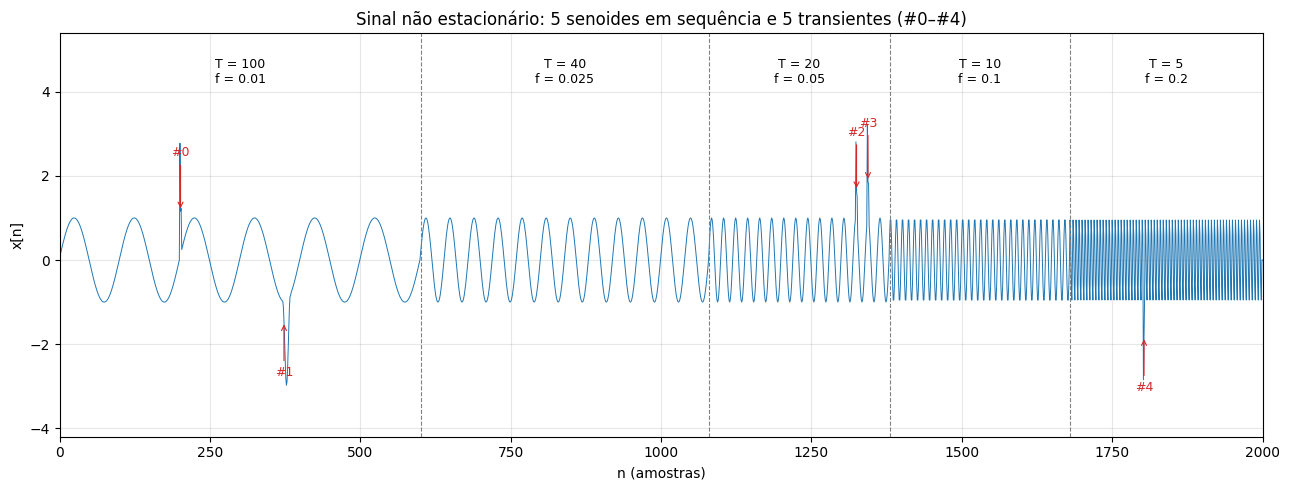

In [ ]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(t_ns, x_ns, lw=0.7)
for p in pos_sin[1:-1]:
    ax.axvline(p, color="gray", ls="--", lw=0.8)
for i in range(5):
    ax.text((pos_sin[i] + pos_sin[i + 1]) / 2, 4.2, f"T = {T_sin[i]}\nf = {1/T_sin[i]:.3g}",
            ha="center", fontsize=9)
for i, (p, a) in enumerate(zip(pos_imp, amp_imp)):
    ax.annotate(f"#{i}", xy=(p + 1, x_ns[p + 1]), xytext=(p + 1, x_ns[p + 1] + (1.3 if a > 0 else -1.3)),
                ha="center", color="tab:red", fontsize=9,
                arrowprops=dict(arrowstyle="->", color="tab:red", lw=0.8))
ax.set_ylim(-4.2, 5.4)
ax.set_xlim(0, N_ns)
ax.set_xlabel("n (amostras)")
ax.set_ylabel("x[n]")
ax.set_title("Sinal não estacionário: 5 senoides em sequência e 5 transientes (#0–#4)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

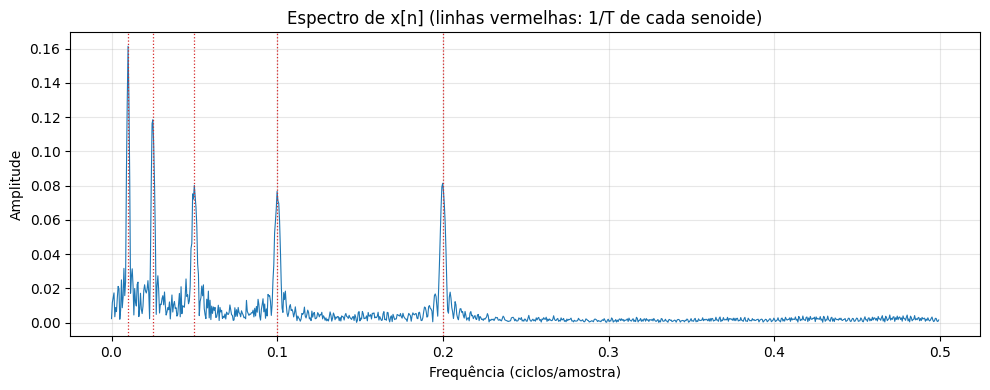

In [ ]:
# Espectro de Fourier do sinal: indica QUAIS frequências existem, mas não QUANDO
f_ns, a_ns = calculate_spectrum(x_ns, 1.0)
plt.figure(figsize=(10, 4))
plt.plot(f_ns, a_ns, lw=0.8)
for T in T_sin:
    plt.axvline(1 / T, color="tab:red", ls=":", lw=0.9)
plt.xlabel("Frequência (ciclos/amostra)")
plt.ylabel("Amplitude")
plt.title("Espectro de x[n] (linhas vermelhas: 1/T de cada senoide)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### (b) Decomposição com a wavelet 7–9 (`bior4.4`): filtros de análise e de síntese

In [ ]:
w_bior = pywt.Wavelet("bior4.4")
filtros_bior = {
    "análise, passa-baixas  h[n]":  w_bior.dec_lo,
    "análise, passa-altas   g[n]":  w_bior.dec_hi,
    "síntese, passa-baixas  h~[n]": w_bior.rec_lo,
    "síntese, passa-altas   g~[n]": w_bior.rec_hi,
}
for nome, h in filtros_bior.items():
    h = np.array(h)
    print(f"{nome}  ({np.count_nonzero(h)} coeficientes não nulos, vetor de {len(h)}):")
    print("   ", np.array2string(h, precision=6, separator=", ", suppress_small=True, max_line_width=120))

coefs_teste = pywt.wavedec(x_ns, "bior4.4", level=5)
x_rec = pywt.waverec(coefs_teste, "bior4.4")[:len(x_ns)]
print("\nReconstrução perfeita? erro máximo =", np.max(np.abs(x_rec - x_ns)))

análise, passa-baixas  h[n]  (9 coeficientes não nulos, vetor de 10):
    [ 0.      ,  0.037828, -0.023849, -0.110624,  0.377403,  0.852699,  0.377403, -0.110624, -0.023849,  0.037828]
análise, passa-altas   g[n]  (7 coeficientes não nulos, vetor de 10):
    [-0.      , -0.064539,  0.040689,  0.418092, -0.788486,  0.418092,  0.040689, -0.064539, -0.      ,  0.      ]
síntese, passa-baixas  h~[n]  (7 coeficientes não nulos, vetor de 10):
    [ 0.      , -0.064539, -0.040689,  0.418092,  0.788486,  0.418092, -0.040689, -0.064539,  0.      ,  0.      ]
síntese, passa-altas   g~[n]  (9 coeficientes não nulos, vetor de 10):
    [ 0.      , -0.037828, -0.023849,  0.110624,  0.377403, -0.852699,  0.377403,  0.110624, -0.023849, -0.037828]

Reconstrução perfeita? erro máximo = 7.637890320211227e-12


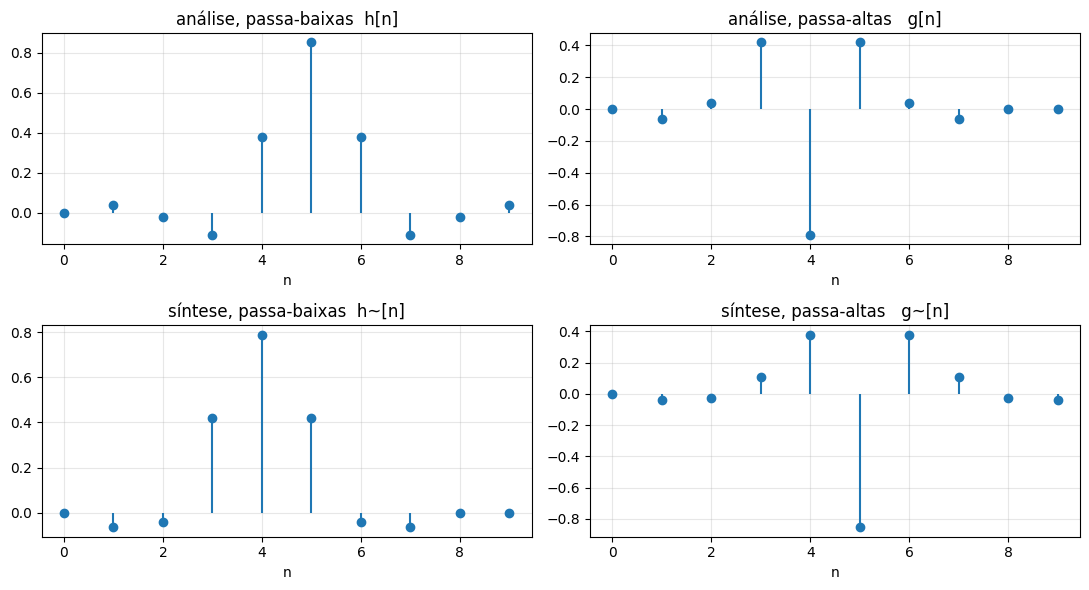

In [ ]:
fig, eixos = plt.subplots(2, 2, figsize=(11, 6))
for ax, (nome, h) in zip(eixos.ravel(), filtros_bior.items()):
    ax.stem(np.arange(len(h)), h, basefmt=" ")
    ax.set_title(nome)
    ax.set_xlabel("n")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### (c) Transformada de wavelet de cinco estágios

Comprimento das subfaixas: {'a5': 71, 'd5': 71, 'd4': 133, 'd3': 258, 'd2': 507, 'd1': 1005}


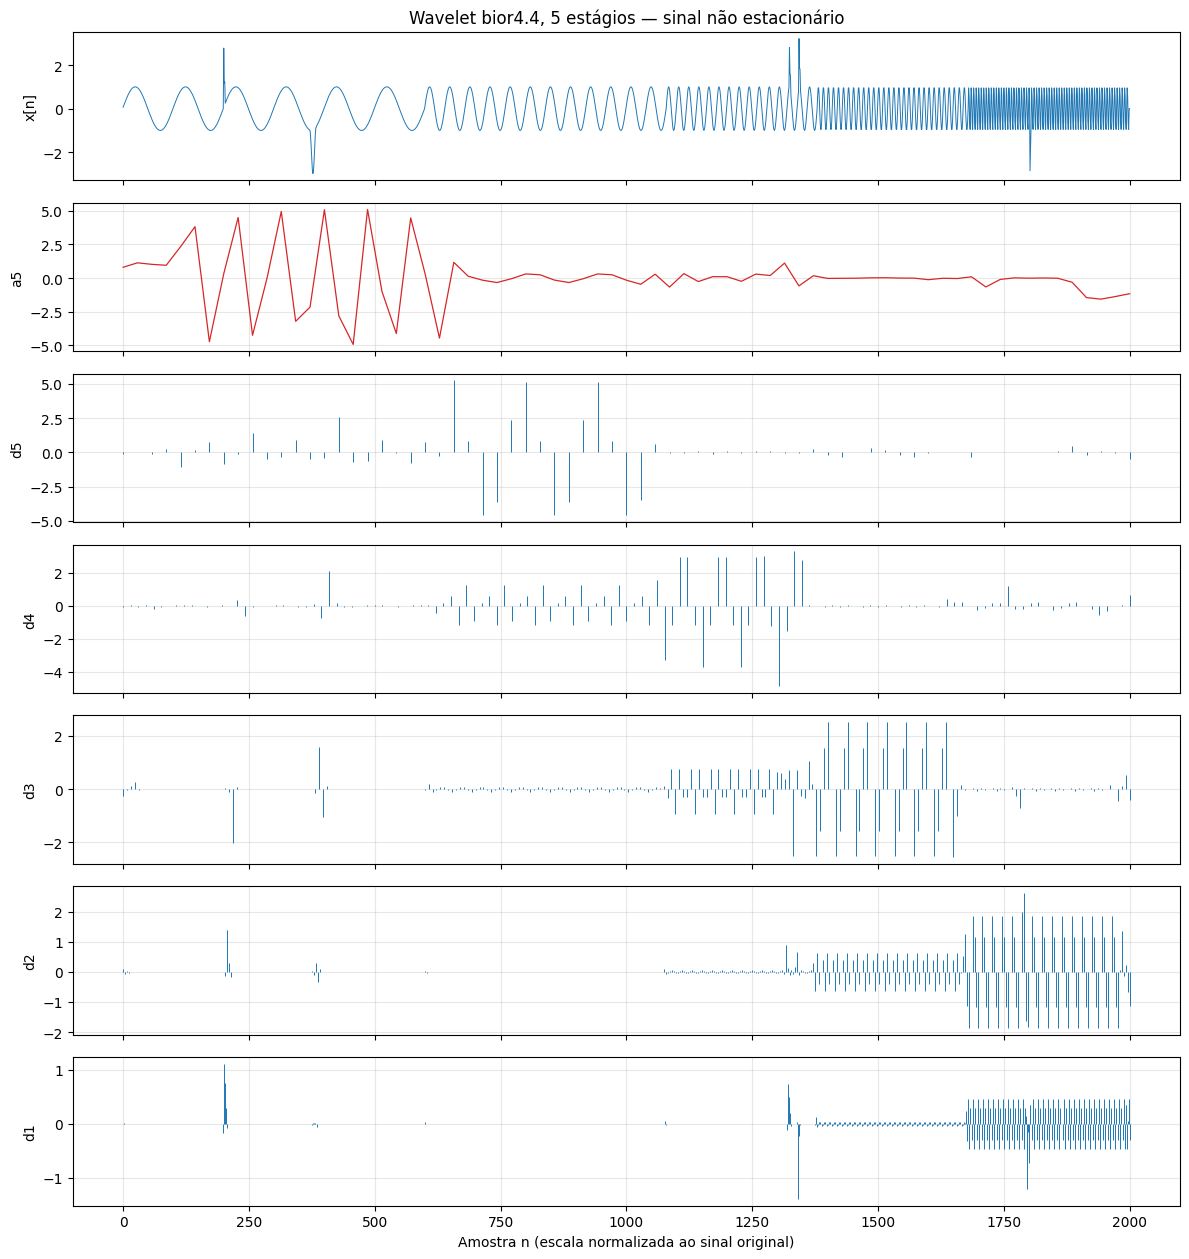

In [ ]:
def plotar_decomposicao(x, coefs, nomes, titulo, nome_sinal="x[n]"):
    """Sinal original, aproximação (último estágio) e detalhes, com a escala de amostras
    de cada subfaixa normalizada ao eixo do sinal original."""
    N = len(x)
    fig, eixos = plt.subplots(len(coefs) + 1, 1, figsize=(12, 1.7 * (len(coefs) + 1) + 0.8), sharex=True)
    eixos[0].plot(np.arange(N), x, lw=0.7)
    eixos[0].set_ylabel(nome_sinal)
    eixos[0].set_title(titulo)
    for ax, c, nome in zip(eixos[1:], coefs, nomes):
        t_norm = np.linspace(0, N - 1, len(c))          # escala de amostras normalizada
        if nome.startswith("a"):
            ax.plot(t_norm, c, lw=0.9, color="tab:red")
        else:
            ax.vlines(t_norm, 0, c, lw=0.7, color="tab:blue")
        ax.set_ylabel(nome)
        ax.grid(True, alpha=0.3)
    eixos[-1].set_xlabel("Amostra n (escala normalizada ao sinal original)")
    plt.tight_layout()
    plt.show()


NIVEL = 5
coefs_ns = pywt.wavedec(x_ns, "bior4.4", level=NIVEL)     # [a5, d5, d4, d3, d2, d1]
nomes_sub = ["a5", "d5", "d4", "d3", "d2", "d1"]
print("Comprimento das subfaixas:", {n: len(c) for n, c in zip(nomes_sub, coefs_ns)})
plotar_decomposicao(x_ns, coefs_ns, nomes_sub, "Wavelet bior4.4, 5 estágios — sinal não estacionário")

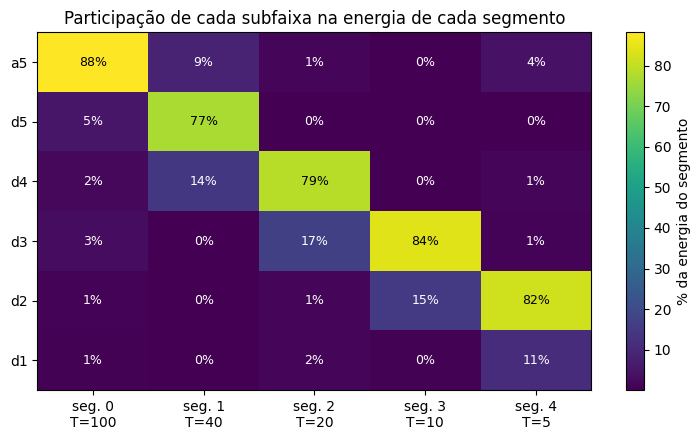

Subfaixa dominante por segmento: ['a5', 'd5', 'd4', 'd3', 'd2']
Subfaixa esperada (f = 1/T):     ['a5', 'd5', 'd4', 'd3', 'd2']

Maiores |d1| (tempo normalizado, valor): [(201, 1.11), (203, 0.75), (1321, 0.74), (1341, -1.39), (1797, -1.21), (1801, -0.72)]
Posições dos transientes #0–#4: [200, 372, 1324, 1343, 1802]


In [ ]:
# Quantificação: em cada segmento senoidal, que parcela da energia dos coeficientes
# cai em cada subfaixa? (cada coeficiente é associado ao seu tempo normalizado)
energia_seg = np.zeros((len(coefs_ns), 5))
for i, c in enumerate(coefs_ns):
    t_norm = np.linspace(0, N_ns, len(c))
    seg = np.clip(np.searchsorted(pos_sin, t_norm, side="right") - 1, 0, 4)
    for s in range(5):
        energia_seg[i, s] = np.sum(c[seg == s] ** 2)
participacao = energia_seg / energia_seg.sum(axis=0, keepdims=True)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
im = ax.imshow(100 * participacao, cmap="viridis", aspect="auto")
ax.set_xticks(range(5))
ax.set_xticklabels([f"seg. {i}\nT={T_sin[i]}" for i in range(5)])
ax.set_yticks(range(len(nomes_sub)))
ax.set_yticklabels(nomes_sub)
for i in range(len(nomes_sub)):
    for s in range(5):
        ax.text(s, i, f"{100*participacao[i, s]:.0f}%", ha="center", va="center",
                color="w" if participacao[i, s] < 0.5 else "k", fontsize=9)
ax.set_title("Participação de cada subfaixa na energia de cada segmento")
fig.colorbar(im, ax=ax, label="% da energia do segmento")
plt.tight_layout()
plt.show()

print("Subfaixa dominante por segmento:", [nomes_sub[int(np.argmax(participacao[:, s]))] for s in range(5)])
print("Subfaixa esperada (f = 1/T):    ", [banda_esperada(1 / T) for T in T_sin])

# Localização temporal dos transientes nos maiores coeficientes de d1
d1 = coefs_ns[-1]
t_d1 = np.linspace(0, N_ns, len(d1))
idx = np.argsort(np.abs(d1))[::-1][:6]
print("\nMaiores |d1| (tempo normalizado, valor):",
      [(int(round(t_d1[i])), round(float(d1[i]), 2)) for i in sorted(idx)])
print("Posições dos transientes #0–#4:", pos_imp.tolist())

## Questão 4 — Remoção de ruído em `leleccum.mat`

### (a) Sinal no tempo e espectro
A frequência de amostragem do sinal não é informada; por isso, as frequências são expressas de
forma **normalizada** (ciclos/amostra, $f_s=1$).


leleccum: N = 4320 amostras | média = 339.5 | desvio-padrão = 107.7 | mín = 121.8 | máx = 547.4


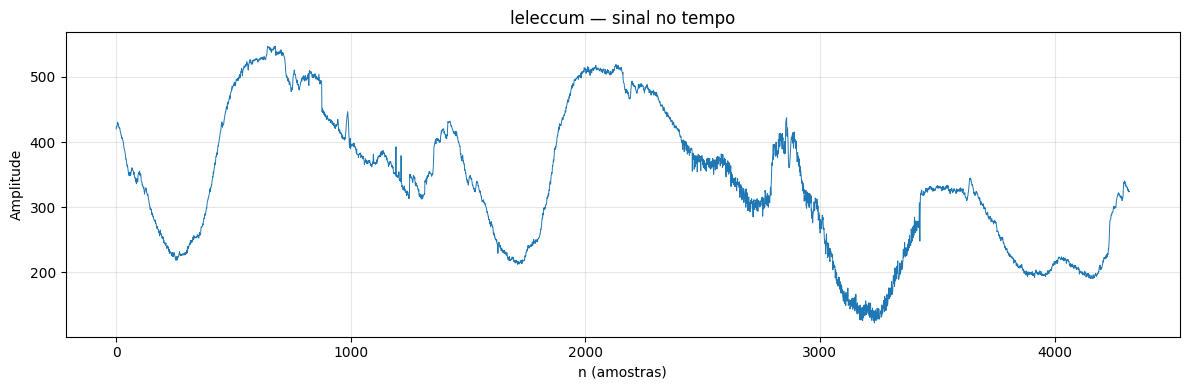

In [ ]:
leleccum = sio.loadmat(os.path.join(PASTA_DADOS, "leleccum.mat"))["leleccum"].ravel().astype(np.float64)
N_L = len(leleccum)
FS_L = 1.0
print(f"leleccum: N = {N_L} amostras | média = {leleccum.mean():.1f} | desvio-padrão = {leleccum.std():.1f} "
      f"| mín = {leleccum.min():.1f} | máx = {leleccum.max():.1f}")

plt.figure(figsize=(12, 4))
plt.plot(leleccum, lw=0.7)
plt.xlabel("n (amostras)")
plt.ylabel("Amplitude")
plt.title("leleccum — sinal no tempo")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

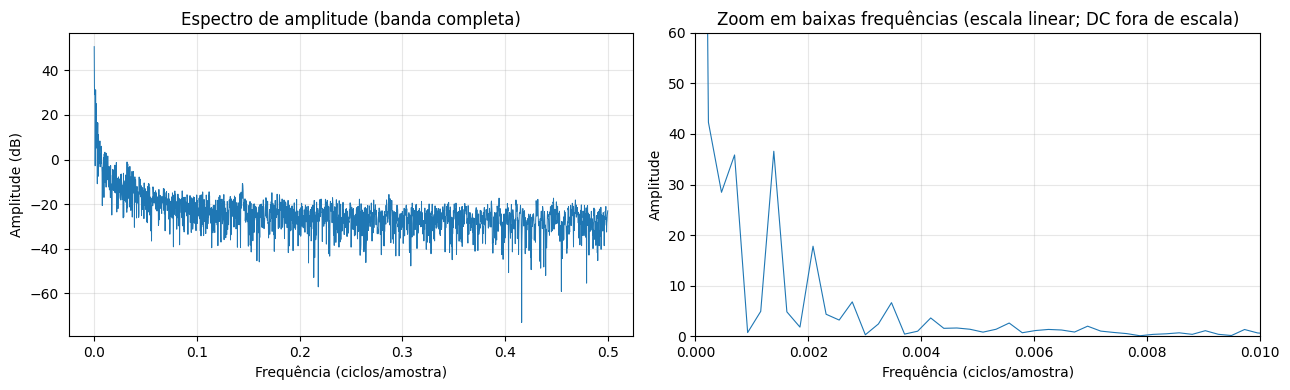

Maiores componentes (sem DC): frequência (ciclos/amostra), período (amostras), amplitude
  0.00023   T =  4320.0   42.31
  0.00046   T =  2160.0   28.46
  0.00069   T =  1440.0   35.85
  0.00139   T =   720.0   36.58
  0.00208   T =   480.0   17.80
  0.00278   T =   360.0   6.79

Energia (sem DC) em f <= 0,01 ciclos/amostra: 99.40%


In [ ]:
f_l, a_l = calculate_spectrum(leleccum, FS_L)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
eixos[0].plot(f_l, 20 * np.log10(a_l + 1e-12), lw=0.7)
eixos[0].set_title("Espectro de amplitude (banda completa)")
eixos[0].set_xlabel("Frequência (ciclos/amostra)")
eixos[0].set_ylabel("Amplitude (dB)")
eixos[0].grid(True, alpha=0.3)
eixos[1].plot(f_l, a_l, lw=0.8)
eixos[1].set_xlim(0, 0.01)
eixos[1].set_ylim(0, 60)
eixos[1].set_title("Zoom em baixas frequências (escala linear; DC fora de escala)")
eixos[1].set_xlabel("Frequência (ciclos/amostra)")
eixos[1].set_ylabel("Amplitude")
eixos[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Maiores componentes (sem a média)
f_p, a_p = calculate_spectrum(leleccum - leleccum.mean(), FS_L)
idx = np.argsort(a_p)[::-1][:6]
print("Maiores componentes (sem DC): frequência (ciclos/amostra), período (amostras), amplitude")
for i in sorted(idx):
    print(f"  {f_p[i]:.5f}   T = {1/f_p[i]:7.1f}   {a_p[i]:.2f}")

# Quanta energia (sem DC) está abaixo de 0,01 ciclos/amostra?
Xr = np.fft.rfft(leleccum - leleccum.mean())
fr = np.fft.rfftfreq(N_L)
e_baixa = np.sum(np.abs(Xr[fr <= 0.01]) ** 2) / np.sum(np.abs(Xr) ** 2)
print(f"\nEnergia (sem DC) em f <= 0,01 ciclos/amostra: {100*e_baixa:.2f}%")

### (b) Decomposição com Daubechies 4 (`db4`): filtros de análise e de síntese

análise, passa-baixas  h[n]  (8 coeficientes):
    [-0.010597,  0.032883,  0.030841, -0.187035, -0.027984,  0.630881,  0.714847,  0.230378]
análise, passa-altas   g[n]  (8 coeficientes):
    [-0.230378,  0.714847, -0.630881, -0.027984,  0.187035,  0.030841, -0.032883, -0.010597]
síntese, passa-baixas  h~[n]  (8 coeficientes):
    [ 0.230378,  0.714847,  0.630881, -0.027984, -0.187035,  0.030841,  0.032883, -0.010597]
síntese, passa-altas   g~[n]  (8 coeficientes):
    [-0.010597, -0.032883,  0.030841,  0.187035, -0.027984, -0.630881,  0.714847, -0.230378]


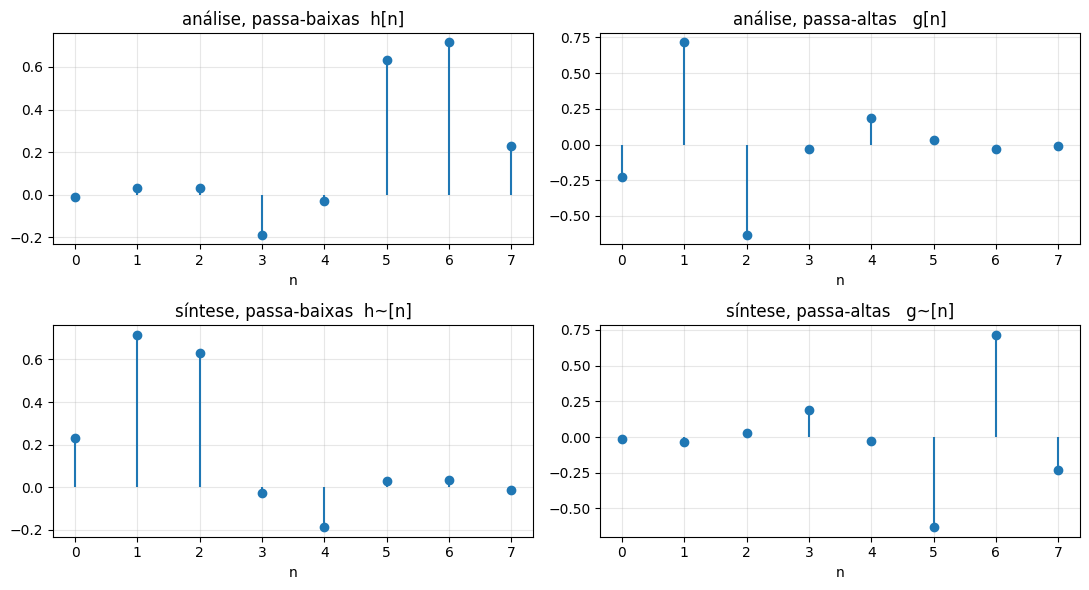

In [ ]:
w_db4 = pywt.Wavelet("db4")
filtros_db4 = {
    "análise, passa-baixas  h[n]":  w_db4.dec_lo,
    "análise, passa-altas   g[n]":  w_db4.dec_hi,
    "síntese, passa-baixas  h~[n]": w_db4.rec_lo,
    "síntese, passa-altas   g~[n]": w_db4.rec_hi,
}
for nome, h in filtros_db4.items():
    h = np.array(h)
    print(f"{nome}  ({len(h)} coeficientes):")
    print("   ", np.array2string(h, precision=6, separator=", ", max_line_width=120))

fig, eixos = plt.subplots(2, 2, figsize=(11, 6))
for ax, (nome, h) in zip(eixos.ravel(), filtros_db4.items()):
    ax.stem(np.arange(len(h)), h, basefmt=" ")
    ax.set_title(nome)
    ax.set_xlabel("n")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### (c) Transformada de wavelet de cinco estágios (db4)

Comprimento das subfaixas: {'a5': 141, 'd5': 141, 'd4': 276, 'd3': 546, 'd2': 1085, 'd1': 2163}
Reconstrução perfeita? erro máximo = 5.684341886080801e-13
  a5: energia = 5.8064e+08 | |c|máx = 3069.52 | desvio-padrão = 601.86
  d5: energia = 7.5077e+04 | |c|máx = 91.81 | desvio-padrão = 23.05
  d4: energia = 3.9783e+04 | |c|máx = 62.91 | desvio-padrão = 12.01
  d3: energia = 2.1241e+04 | |c|máx = 36.48 | desvio-padrão = 6.24
  d2: energia = 2.3302e+04 | |c|máx = 32.94 | desvio-padrão = 4.63
  d1: energia = 2.7789e+04 | |c|máx = 30.45 | desvio-padrão = 3.58


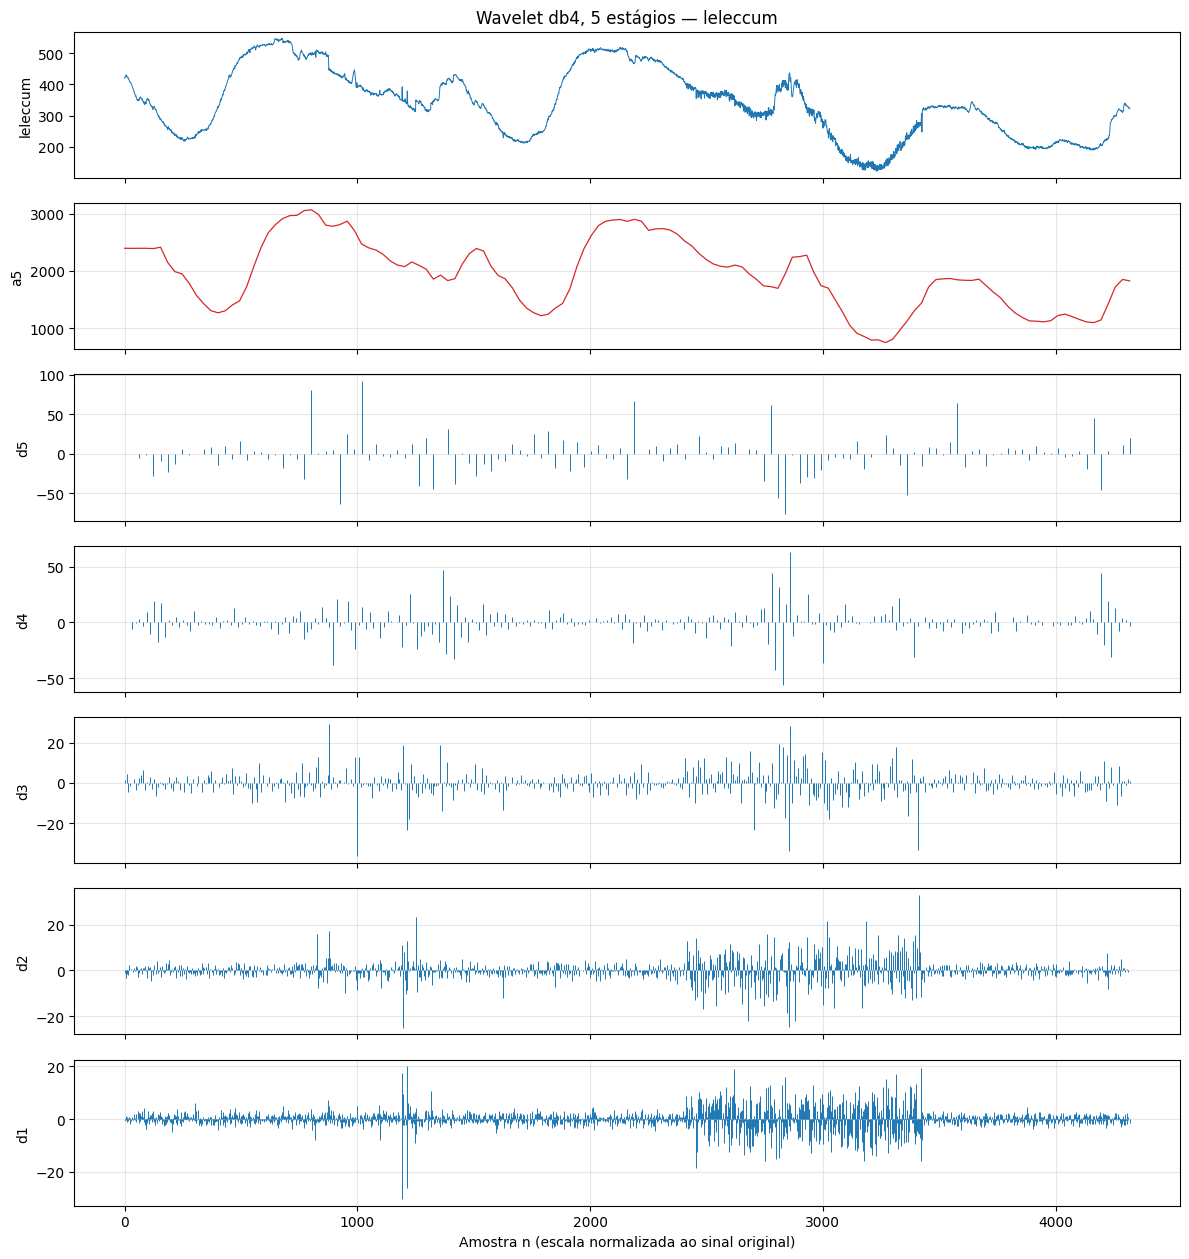

In [ ]:
coefs_L = pywt.wavedec(leleccum, "db4", level=5)           # [a5, d5, d4, d3, d2, d1]
nomes_L = ["a5", "d5", "d4", "d3", "d2", "d1"]
print("Comprimento das subfaixas:", {n: len(c) for n, c in zip(nomes_L, coefs_L)})
print("Reconstrução perfeita? erro máximo =",
      np.max(np.abs(pywt.waverec(coefs_L, "db4")[:N_L] - leleccum)))
for n, c in zip(nomes_L, coefs_L):
    print(f"  {n}: energia = {np.sum(c**2):.4e} | |c|máx = {np.max(np.abs(c)):.2f} | desvio-padrão = {np.std(c):.2f}")
plotar_decomposicao(leleccum, coefs_L, nomes_L, "Wavelet db4, 5 estágios — leleccum", nome_sinal="leleccum")

### (d) Remoção de ruído por limiarização dos coeficientes de wavelet

**Estimativa do ruído e limiar universal (Donoho–Johnstone).** O ruído aparece principalmente na
subfaixa de maior frequência, $d_1$. Estima-se $\hat\sigma=\operatorname{mediana}(|d_1|)/0{,}6745$
(estimador robusto, MAD) e adota-se $\lambda_u=\hat\sigma\sqrt{2\ln N}$. A limiarização **suave**
faz $c\mapsto\operatorname{sign}(c)\,(|c|-\lambda)_+$; a **dura** faz $c\mapsto c\,\mathbb{1}[|c|>\lambda]$.
O limiar é $\lambda=\alpha\,\lambda_u$, com $\alpha$ variado.


In [ ]:
def estimar_sigma(d1):
    return np.median(np.abs(d1)) / 0.6745

def limiar_universal(sigma, N):
    return sigma * np.sqrt(2.0 * np.log(N))

def limiarizar_coeficientes(coefs, limiar, modo="soft", incluir_aproximacao=False):
    """Limiariza os detalhes (e, opcionalmente, a aproximação)."""
    novo = [pywt.threshold(coefs[0], limiar, mode=modo) if incluir_aproximacao else coefs[0].copy()]
    novo += [pywt.threshold(d, limiar, mode=modo) for d in coefs[1:]]
    return novo

def reconstruir(coefs, N, wavelet="db4"):
    return pywt.waverec(coefs, wavelet)[:N]

def avaliar(rotulo, x, x_hat, n_nao_nulos, n_total, sigma):
    """Métricas sem sinal limpo de referência:
    - % de coeficientes zerados
    - variância do resíduo x - x_hat e sua razão com σ̂² (≈ 1 se só ruído foi removido)
    - rugosidade: desvio-padrão da primeira diferença (cai quando o ruído é removido)
    - viés: média do resíduo (a variância não enxerga um deslocamento constante)"""
    res = x - x_hat
    m = dict(zerados=100 * (1 - n_nao_nulos / n_total), var_res=np.var(res),
             razao=np.var(res) / sigma ** 2, rug=np.std(np.diff(x_hat)), vies=np.mean(res))
    print(f"{rotulo:<40} {m['zerados']:6.1f}% {m['var_res']:9.3f} {m['razao']:7.2f} {m['rug']:9.3f} {m['vies']:8.3f}")
    return m

def cabecalho_tabela():
    print(f"{'configuração':<40} {'zerad.':>7} {'var(res)':>9} {'/σ̂²':>7} {'rugosid.':>9} {'viés':>8}")


sigma_hat = estimar_sigma(coefs_L[-1])
lambda_u = limiar_universal(sigma_hat, N_L)
n_total_coef = sum(len(c) for c in coefs_L)
print(f"σ̂ (MAD de d1) = {sigma_hat:.3f} | λ_u = σ̂·√(2 ln N) = {lambda_u:.3f}")
print(f"rugosidade do sinal original (std da 1ª diferença) = {np.std(np.diff(leleccum)):.3f}\n")

σ̂ (MAD de d1) = 1.866 | λ_u = σ̂·√(2 ln N) = 7.635
rugosidade do sinal original (std da 1ª diferença) = 5.452



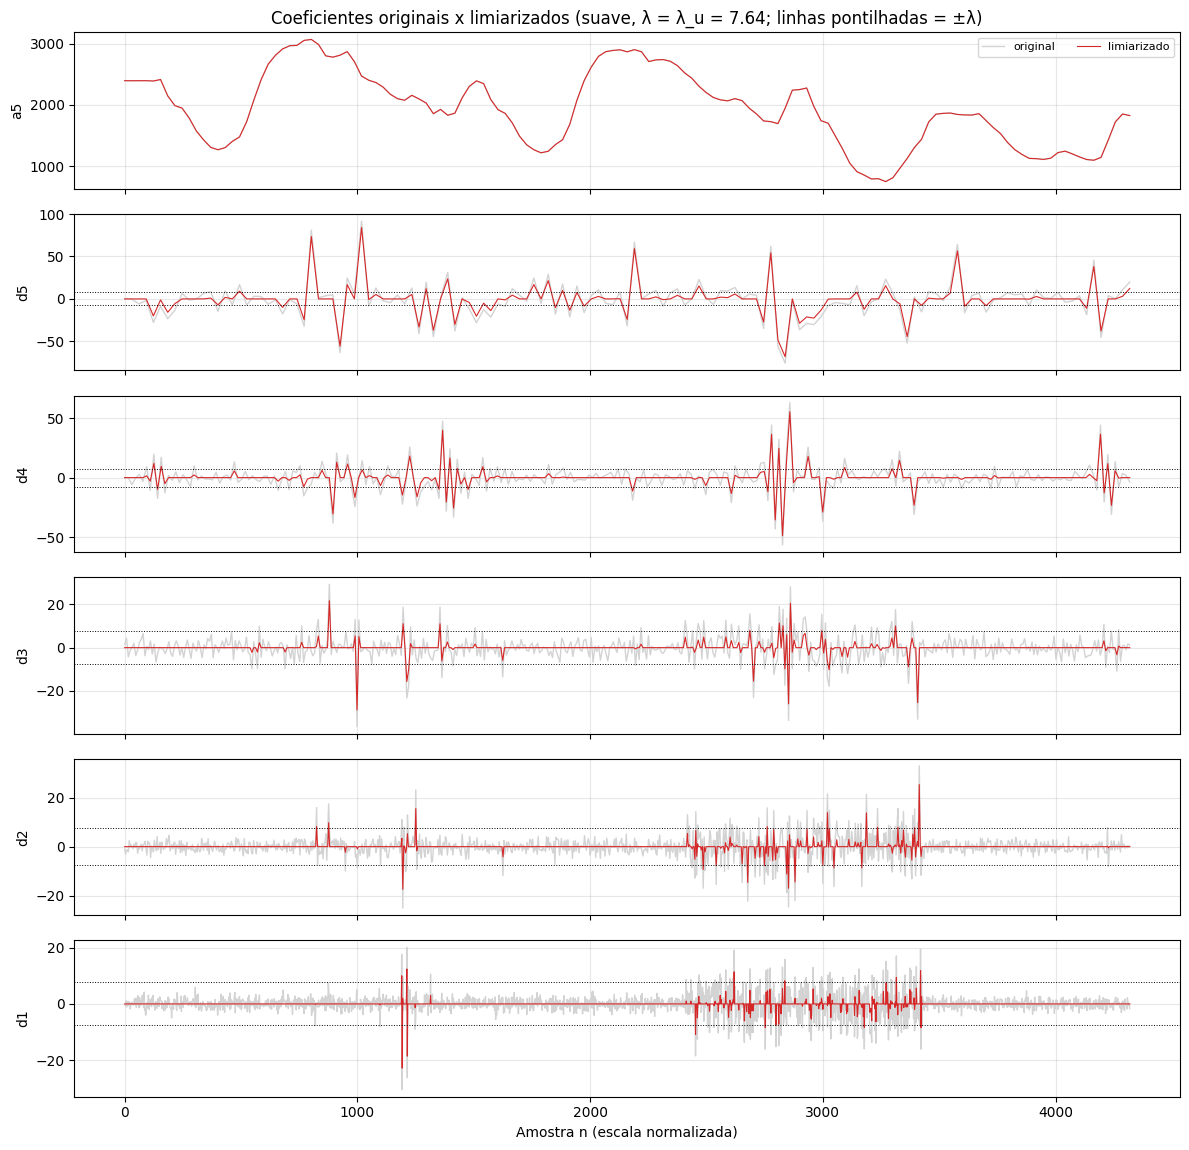

configuração                              zerad.  var(res)    /σ̂²  rugosid.     viés
  a5:   0.0% zerados | energia 100.00% da original
  d5:  47.5% zerados | energia  66.14% da original
  d4:  71.7% zerados | energia  49.67% da original
  d3:  85.7% zerados | energia  24.93% da original
  d2:  90.7% zerados | energia  17.55% da original
  d1:  93.8% zerados | energia  10.89% da original


In [ ]:
# Detalhes e aproximação ORIGINAIS x LIMIARIZADOS (limiar universal, suave)
coefs_thr = limiarizar_coeficientes(coefs_L, lambda_u, "soft")

fig, eixos = plt.subplots(len(coefs_L), 1, figsize=(12, 1.8 * len(coefs_L) + 0.8), sharex=True)
for ax, c0, c1, nome in zip(eixos, coefs_L, coefs_thr, nomes_L):
    t_norm = np.linspace(0, N_L - 1, len(c0))
    ax.plot(t_norm, c0, color="lightgray", lw=1.0, label="original")
    ax.plot(t_norm, c1, color="tab:red", lw=0.8, label="limiarizado")
    if nome != "a5":
        ax.axhline(lambda_u, color="k", ls=":", lw=0.7)
        ax.axhline(-lambda_u, color="k", ls=":", lw=0.7)
    ax.set_ylabel(nome)
    ax.grid(True, alpha=0.3)
eixos[0].legend(fontsize=8, ncol=2)
eixos[0].set_title(f"Coeficientes originais x limiarizados (suave, λ = λ_u = {lambda_u:.2f}; linhas pontilhadas = ±λ)")
eixos[-1].set_xlabel("Amostra n (escala normalizada)")
plt.tight_layout()
plt.show()

cabecalho_tabela()
for nome, c0, c1 in zip(nomes_L, coefs_L, coefs_thr):
    print(f"  {nome}: {100*(1-np.count_nonzero(c1)/len(c1)):5.1f}% zerados | energia {np.sum(c1**2)/np.sum(c0**2)*100:6.2f}% da original")

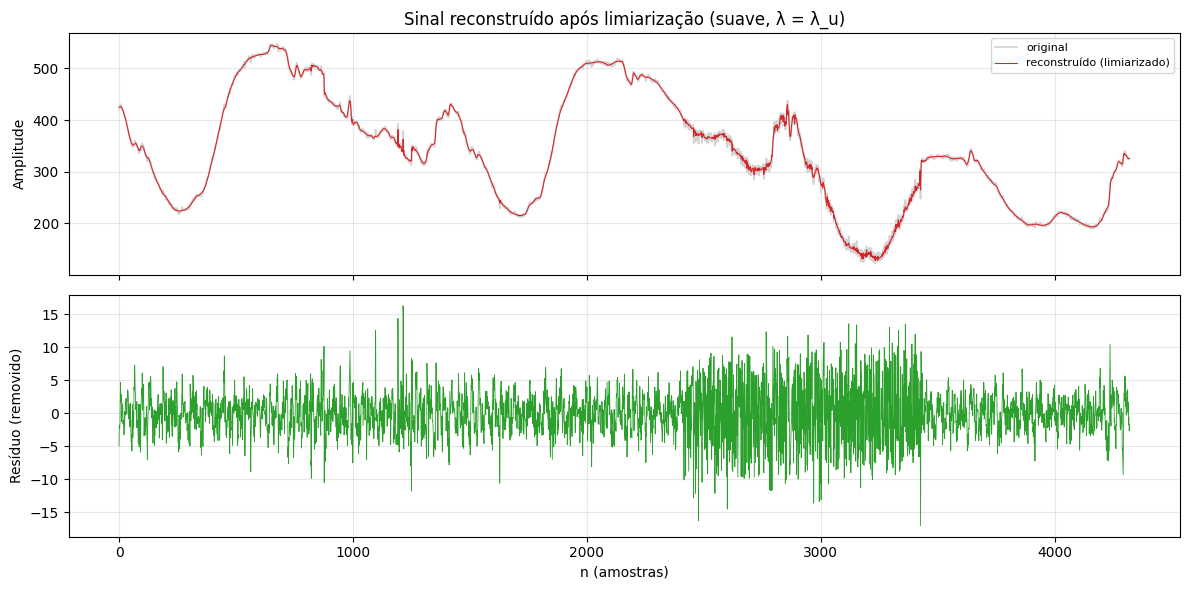

In [ ]:
# Sinal reconstruído (limiar universal, suave) e resíduo
x_dn = reconstruir(coefs_thr, N_L)
fig, eixos = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
eixos[0].plot(leleccum, color="lightgray", lw=1.2, label="original")
eixos[0].plot(x_dn, color="tab:red", lw=0.8, label="reconstruído (limiarizado)")
eixos[0].set_ylabel("Amplitude")
eixos[0].legend(fontsize=8)
eixos[0].set_title("Sinal reconstruído após limiarização (suave, λ = λ_u)")
eixos[1].plot(leleccum - x_dn, lw=0.6, color="tab:green")
eixos[1].set_ylabel("Resíduo (removido)")
eixos[1].set_xlabel("n (amostras)")
for ax in eixos:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Limiarização SUAVE dos detalhes:
configuração                              zerad.  var(res)    /σ̂²  rugosid.     viés
suave, α = 0.25 (λ = 1.91)                 52.4%     2.159    0.62     4.206    0.000
suave, α = 0.5 (λ = 3.82)                  73.8%     5.505    1.58     3.359    0.001
suave, α = 1 (λ = 7.64)                    86.1%    12.132    3.48     2.221    0.001
suave, α = 2 (λ = 15.27)                   93.8%    21.433    6.16     1.301    0.001


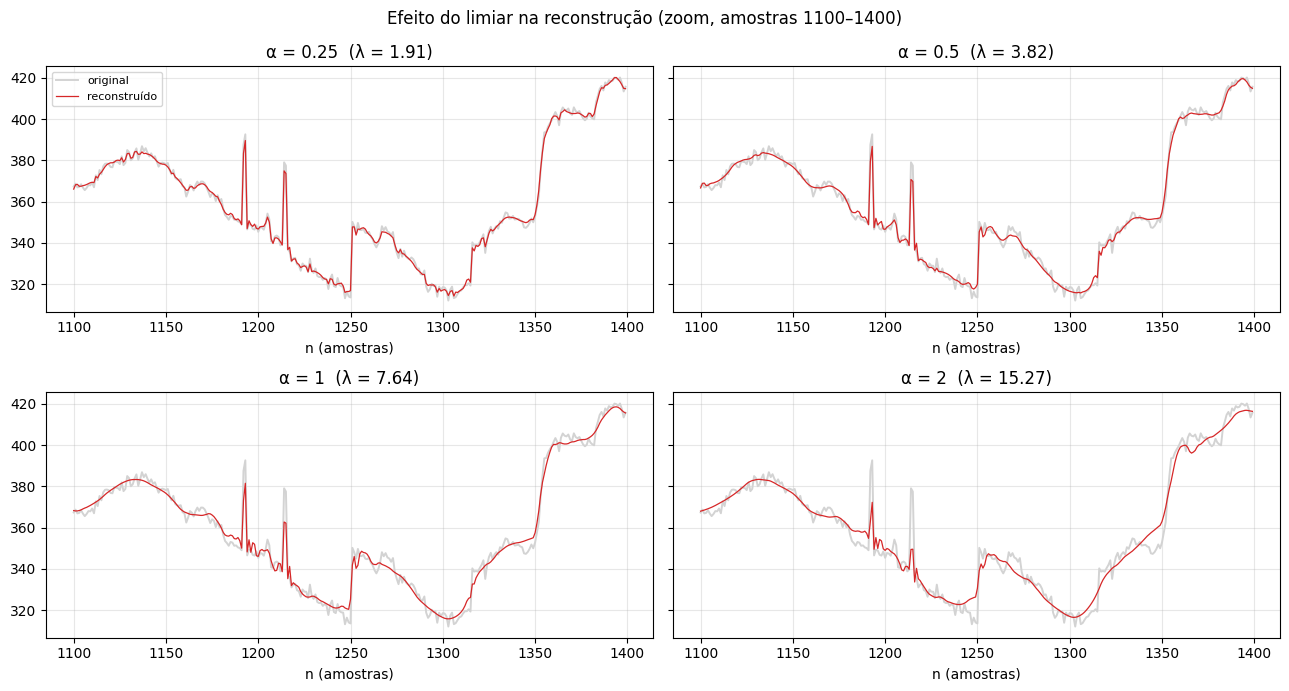

In [ ]:
# Variação do limiar: λ = α λ_u (limiarização suave nos detalhes)
ALFAS = [0.25, 0.5, 1.0, 2.0]
JANELA = (1100, 1400)   # região com variações abruptas, para visualização
print("Limiarização SUAVE dos detalhes:")
cabecalho_tabela()
sweep = {}
fig, eixos = plt.subplots(2, 2, figsize=(13, 7), sharey=True)
for ax, a in zip(eixos.ravel(), ALFAS):
    c = limiarizar_coeficientes(coefs_L, a * lambda_u, "soft")
    xh = reconstruir(c, N_L)
    nz = sum(np.count_nonzero(k) for k in c)
    sweep[a] = avaliar(f"suave, α = {a:g} (λ = {a*lambda_u:.2f})", leleccum, xh, nz, n_total_coef, sigma_hat)
    ax.plot(np.arange(*JANELA), leleccum[JANELA[0]:JANELA[1]], color="lightgray", lw=1.4, label="original")
    ax.plot(np.arange(*JANELA), xh[JANELA[0]:JANELA[1]], color="tab:red", lw=0.9, label="reconstruído")
    ax.set_title(f"α = {a:g}  (λ = {a*lambda_u:.2f})")
    ax.set_xlabel("n (amostras)")
    ax.grid(True, alpha=0.3)
eixos[0, 0].legend(fontsize=8)
plt.suptitle("Efeito do limiar na reconstrução (zoom, amostras 1100–1400)")
plt.tight_layout()
plt.show()

Estratégias com λ = λ_u:
configuração                              zerad.  var(res)    /σ̂²  rugosid.     viés
suave, só detalhes                         86.1%    12.132    3.48     2.221    0.001
dura, só detalhes                          86.1%     5.884    1.69     4.483    0.001
suave, detalhes + aproximação              86.1%    12.132    3.48     2.221    1.351
dura, detalhes + aproximação               86.1%     5.884    1.69     4.483    0.001


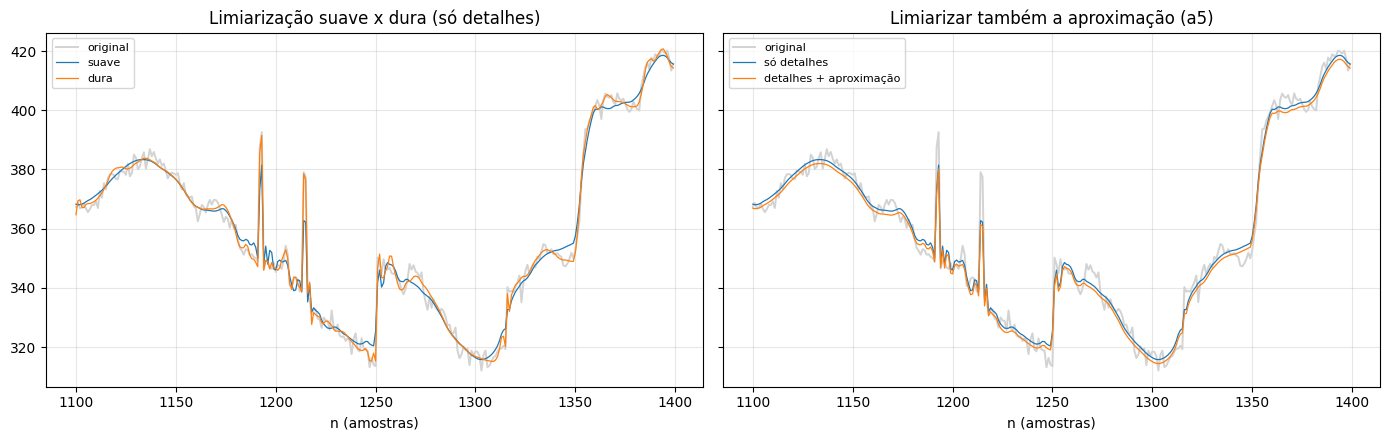

In [ ]:
# Outras estratégias com λ = λ_u: dura x suave; limiarizar também a aproximação
print("Estratégias com λ = λ_u:")
cabecalho_tabela()
estrategias = {}
for rotulo, modo, inc in [("suave, só detalhes", "soft", False), ("dura, só detalhes", "hard", False),
                          ("suave, detalhes + aproximação", "soft", True),
                          ("dura, detalhes + aproximação", "hard", True)]:
    c = limiarizar_coeficientes(coefs_L, lambda_u, modo, incluir_aproximacao=inc)
    xh = reconstruir(c, N_L)
    nz = sum(np.count_nonzero(k) for k in c)
    estrategias[rotulo] = xh
    avaliar(rotulo, leleccum, xh, nz, n_total_coef, sigma_hat)

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
xs = np.arange(*JANELA)
eixos[0].plot(xs, leleccum[JANELA[0]:JANELA[1]], color="lightgray", lw=1.4, label="original")
eixos[0].plot(xs, estrategias["suave, só detalhes"][JANELA[0]:JANELA[1]], lw=0.9, label="suave")
eixos[0].plot(xs, estrategias["dura, só detalhes"][JANELA[0]:JANELA[1]], lw=0.9, label="dura")
eixos[0].set_title("Limiarização suave x dura (só detalhes)")
eixos[1].plot(xs, leleccum[JANELA[0]:JANELA[1]], color="lightgray", lw=1.4, label="original")
eixos[1].plot(xs, estrategias["suave, só detalhes"][JANELA[0]:JANELA[1]], lw=0.9, label="só detalhes")
eixos[1].plot(xs, estrategias["suave, detalhes + aproximação"][JANELA[0]:JANELA[1]], lw=0.9, label="detalhes + aproximação")
eixos[1].set_title("Limiarizar também a aproximação (a5)")
for ax in eixos:
    ax.set_xlabel("n (amostras)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### (e) Limiarização na DFT e comparação com o item anterior

A DFT é calculada em escala ortonormal, $X[k]=\tfrac1{\sqrt N}\sum_n x[n]e^{-j2\pi kn/N}$ (ruído branco de
variância $\sigma^2$ produz $\mathbb{E}|X[k]|^2=\sigma^2$). Aplica-se **limiarização dura** ao módulo,
mantendo $X[k]$ se $|X[k]|\geq\lambda_F$, com $\lambda_F=\alpha\,\hat\sigma\sqrt{2\ln N}$ e o mesmo
$\hat\sigma$ do item (d). Como cada bin complexo vale 2 números reais (exceto DC e Nyquist), a contagem
de coeficientes é feita em **números reais**, para comparação justa com a wavelet. Além da variação de $\alpha$,
compara-se a DFT com a wavelet **para o mesmo número de coeficientes não nulos**.


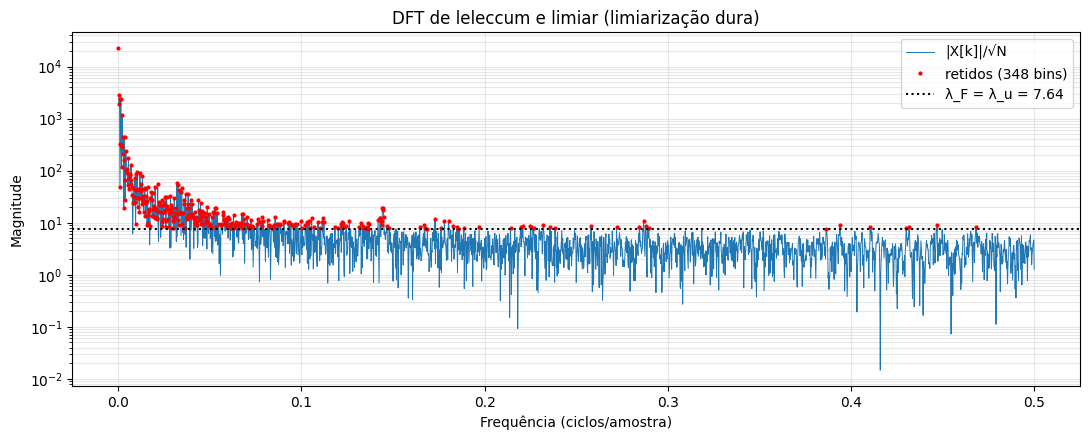

In [ ]:
def pesos_reais_dft(N):
    """Números reais por bin de rfft: 1 para DC (e Nyquist, se N par), 2 para os demais."""
    p = np.full(N // 2 + 1, 2)
    p[0] = 1
    if N % 2 == 0:
        p[-1] = 1
    return p

def limiarizar_dft(x, limiar):
    N = len(x)
    X = np.fft.rfft(x) / np.sqrt(N)                  # escala ortonormal
    mascara = np.abs(X) >= limiar
    x_hat = np.fft.irfft(np.where(mascara, X, 0) * np.sqrt(N), n=N)
    return x_hat, mascara, int(np.sum(pesos_reais_dft(N) * mascara))

def limiar_dft_para_n_reais(x, n_alvo):
    """Limiar tal que o número de reais retidos seja o maior possível sem exceder n_alvo."""
    N = len(x)
    mag = np.abs(np.fft.rfft(x)) / np.sqrt(N)
    ordem = np.argsort(mag)[::-1]
    acum = np.cumsum(pesos_reais_dft(N)[ordem])
    k = max(int(np.searchsorted(acum, n_alvo, side="right")), 1)
    return mag[ordem[k - 1]]


# Espectro (escala ortonormal) com o limiar λ_F (α = 1)
mag_dft = np.abs(np.fft.rfft(leleccum)) / np.sqrt(N_L)
f_dft = np.fft.rfftfreq(N_L)
x_f1, mascara1, n_reais1 = limiarizar_dft(leleccum, lambda_u)

plt.figure(figsize=(11, 4.5))
plt.semilogy(f_dft[1:], mag_dft[1:], lw=0.7, label="|X[k]|/√N")
plt.semilogy(f_dft[mascara1], mag_dft[mascara1], "r.", ms=4, label=f"retidos ({mascara1.sum()} bins)")
plt.axhline(lambda_u, color="k", ls=":", label=f"λ_F = λ_u = {lambda_u:.2f}")
plt.xlabel("Frequência (ciclos/amostra)")
plt.ylabel("Magnitude")
plt.title("DFT de leleccum e limiar (limiarização dura)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Limiarização DURA na DFT:
configuração                              zerad.  var(res)    /σ̂²  rugosid.     viés
DFT, α = 0.25 (λ_F = 1.91)                 16.9%     0.286    0.08     5.397    0.000
DFT, α = 0.5 (λ_F = 3.82)                  49.8%     3.094    0.89     4.786    0.000
DFT, α = 1 (λ_F = 7.64)                    83.9%    12.809    3.68     2.475    0.000
DFT, α = 2 (λ_F = 15.27)                   93.6%    23.090    6.63     1.396    0.000


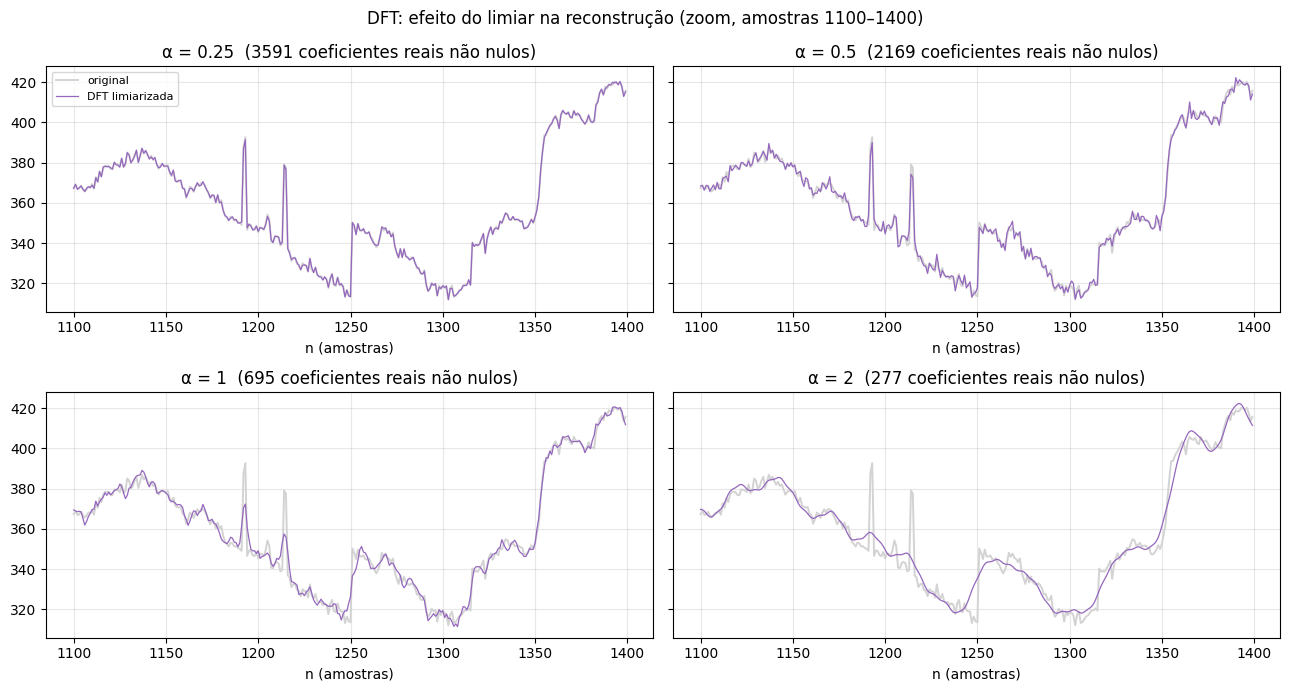

In [ ]:
# Variação do limiar na DFT: λ_F = α λ_u
print("Limiarização DURA na DFT:")
cabecalho_tabela()
fig, eixos = plt.subplots(2, 2, figsize=(13, 7), sharey=True)
for ax, a in zip(eixos.ravel(), ALFAS):
    xh, mascara, n_reais = limiarizar_dft(leleccum, a * lambda_u)
    avaliar(f"DFT, α = {a:g} (λ_F = {a*lambda_u:.2f})", leleccum, xh, n_reais, N_L, sigma_hat)
    ax.plot(np.arange(*JANELA), leleccum[JANELA[0]:JANELA[1]], color="lightgray", lw=1.4, label="original")
    ax.plot(np.arange(*JANELA), xh[JANELA[0]:JANELA[1]], color="tab:purple", lw=0.9, label="DFT limiarizada")
    ax.set_title(f"α = {a:g}  ({n_reais} coeficientes reais não nulos)")
    ax.set_xlabel("n (amostras)")
    ax.grid(True, alpha=0.3)
eixos[0, 0].legend(fontsize=8)
plt.suptitle("DFT: efeito do limiar na reconstrução (zoom, amostras 1100–1400)")
plt.tight_layout()
plt.show()


α = 1: wavelet com 606 coeficientes não nulos; DFT casada com 605
configuração                              zerad.  var(res)    /σ̂²  rugosid.     viés
wavelet db4 (suave)                        86.1%    12.132    3.48     2.221    0.001
DFT (dura), mesmo nº de coeficientes       86.0%    14.144    4.06     2.173    0.000

α = 0.5: wavelet com 1139 coeficientes não nulos; DFT casada com 1137
configuração                              zerad.  var(res)    /σ̂²  rugosid.     viés
wavelet db4 (suave)                        73.8%     5.505    1.58     3.359    0.001
DFT (dura), mesmo nº de coeficientes       73.7%     8.342    2.40     3.548    0.000


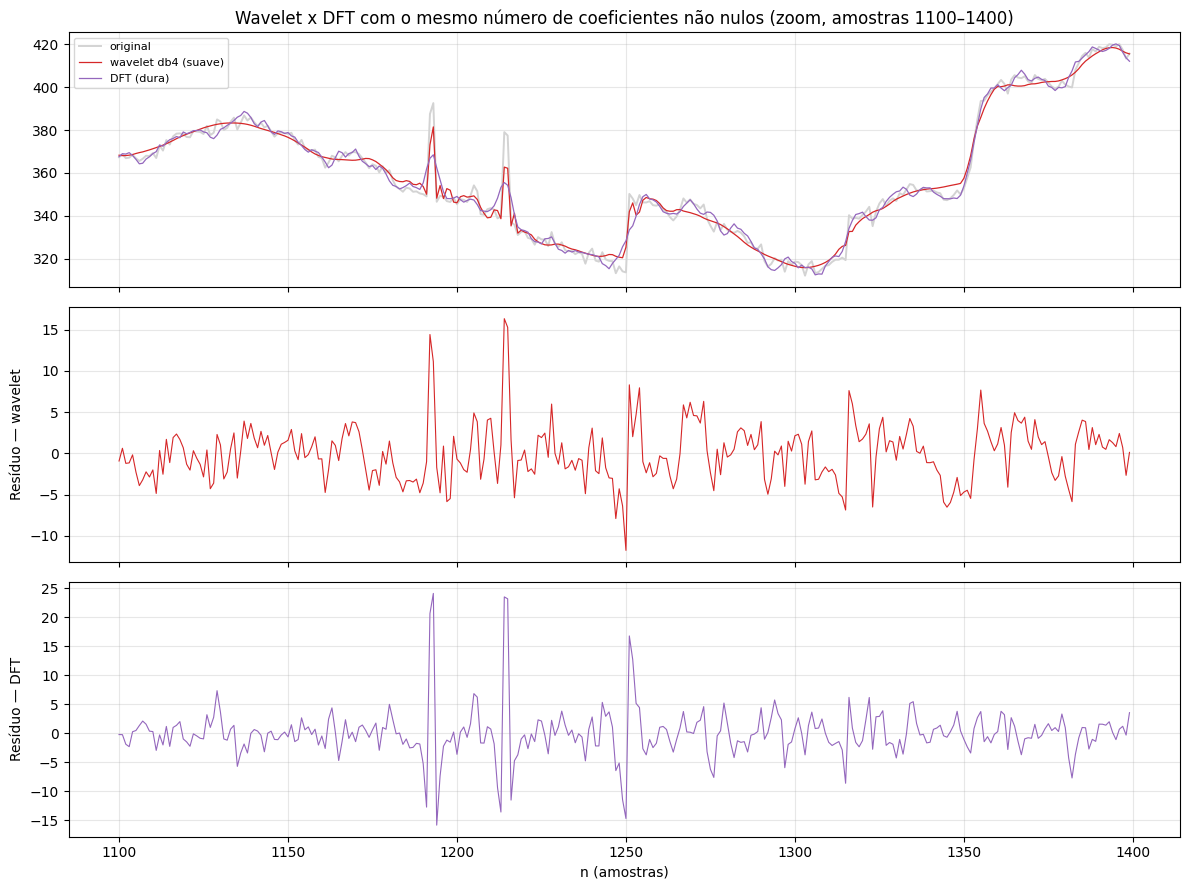

In [ ]:
# Comparação com o MESMO número de coeficientes não nulos
for a in [1.0, 0.5]:
    c_w = limiarizar_coeficientes(coefs_L, a * lambda_u, "soft")
    x_w = reconstruir(c_w, N_L)
    n_w = sum(np.count_nonzero(k) for k in c_w)
    lam_f = limiar_dft_para_n_reais(leleccum, n_w)
    x_f, mascara, n_f = limiarizar_dft(leleccum, lam_f)
    print(f"\nα = {a:g}: wavelet com {n_w} coeficientes não nulos; DFT casada com {n_f}")
    cabecalho_tabela()
    avaliar("wavelet db4 (suave)", leleccum, x_w, n_w, n_total_coef, sigma_hat)
    avaliar("DFT (dura), mesmo nº de coeficientes", leleccum, x_f, n_f, N_L, sigma_hat)
    if a == 1.0:
        x_w_cmp, x_f_cmp = x_w, x_f

fig, eixos = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
xs = np.arange(*JANELA)
eixos[0].plot(xs, leleccum[JANELA[0]:JANELA[1]], color="lightgray", lw=1.4, label="original")
eixos[0].plot(xs, x_w_cmp[JANELA[0]:JANELA[1]], color="tab:red", lw=0.9, label="wavelet db4 (suave)")
eixos[0].plot(xs, x_f_cmp[JANELA[0]:JANELA[1]], color="tab:purple", lw=0.9, label="DFT (dura)")
eixos[0].set_title("Wavelet x DFT com o mesmo número de coeficientes não nulos (zoom, amostras 1100–1400)")
eixos[0].legend(fontsize=8)
eixos[1].plot(xs, (leleccum - x_w_cmp)[JANELA[0]:JANELA[1]], color="tab:red", lw=0.8)
eixos[1].set_ylabel("Resíduo — wavelet")
eixos[2].plot(xs, (leleccum - x_f_cmp)[JANELA[0]:JANELA[1]], color="tab:purple", lw=0.8)
eixos[2].set_ylabel("Resíduo — DFT")
eixos[2].set_xlabel("n (amostras)")
for ax in eixos:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()